# EDA y perfilamiento: violencia contra las mujeres en Bucaramanga (ODS 5)

Proyecto ETL - Segunda entrega

En este notebook hacemos el análisis exploratorio de datos (EDA) **antes de transformar**. La regla es simple: aquí solo se mira, se cuenta y se grafica. No se limpia ningún valor, no se cambian tipos de datos y no se unen las fuentes. Todo lo que se ve es lo que llegó de cada fuente tal cual, y lo que encontremos se convierte al final en las reglas que va a aplicar la transformación del pipeline

El enfoque de esta entrega es **Bucaramanga (código DANE 68001)**. Trabajamos con 4 fuentes y siempre las revisamos en el mismo orden:

| # | Fuente | Cómo se obtiene | Qué es cada fila |
|---|---|---|---|
| 1 | Boletines mensuales de delitos del Observatorio de Seguridad (OSEC) de la Alcaldía de Bucaramanga | Web scraping (página HTML + PDF) | Una comuna, en un boletín, para un delito y un bloque (acumulado o mes) |
| 2 | Violencia intrafamiliar 2015-2024 de Medicina Legal (datos.gov.co, conjunto `ers2-kerr`) | API REST (Socrata) | Un caso de violencia |
| 3 | Encuesta Nacional de Calidad de Vida 2024 del DANE, tabla de vivienda (`vivienda.CSV`) | Archivo CSV local | Una vivienda |
| 4 | Histórico de violencia de género de Bucaramanga (SIVIGILA), el dataset de la primera entrega | Archivo CSV local | Un caso de violencia |

Lo que pide el enunciado para el EDA y dónde lo resolvemos:

- Tipos de datos, valores faltantes, duplicados y valores atípicos: en la Parte 2 (scraping), Parte 3 (API), Parte 4 (vivienda) y Parte 5 (dataset de la primera entrega), cada fuente con las mismas preguntas
- Variables clave, estadísticas básicas y gráficas (distribuciones y categorías principales): al final de cada una de esas partes
- Hallazgos que guían la transformación: en la Parte 6, escritos como reglas concretas

Ruta del notebook:

- Antes de empezar: qué nos faltaba y qué corregimos en esta versión
- Parte 0: preparación (librerías, rutas y funciones de ayuda)
- Parte 1: extracción de las 4 fuentes y volumen total de datos
- Parte 2: fuente 1, scraping del OSEC
- Parte 3: fuente 2, API de Medicina Legal
- Parte 4: fuente 3, CSV de vivienda
- Parte 5: fuente 4, dataset de la primera entrega
- Parte 6: hallazgos y reglas de transformación


### 1.objetivos refinados con las fuentes nuevas



- **Objetivo general:** construir un pipeline ETL automatizado (Airflow) y validado (Great Expectations) que integre fuentes oficiales sobre violencia contra las mujeres en Bucaramanga, para entender cómo ha evolucionado entre 2015 y 2026, dónde se concentra, cómo se manifiesta y en qué contexto socioeconómico ocurre, como insumo para estrategias de prevención (ODS 5)

| Objetivo específico | Fuentes que lo responden | Qué miramos en el EDA |
|---|---|---|
| Tendencia en el tiempo (2015-2026) | API (2015-2024), OSEC (2024-2026), SIVIGILA | Años y meses que cubre cada fuente y si hay huecos |
| Comunas con más casos y con aumentos recientes | OSEC y SIVIGILA | Cómo viene escrita la comuna en cada fuente y si se pueden unir |
| Cómo se manifiesta (tipo, agresor, turno, escenario, edad) | SIVIGILA y API | Categorías de cada variable, valores sin dato y formatos de hora |
| Casos fatales vs. no fatales | SIVIGILA | La variable de condición final |
| Contexto de vivienda y estrato | ECV 2024 | Calidad del estrato y zona de la vivienda |
| Solo datos validados en el Data Warehouse | Las 4 | Reglas que luego se vuelven expectativas de Great Expectations |



## Parte 0. Preparación

Cargamos las librerías, definimos las rutas y las direcciones de las fuentes, y escribimos unas funciones de ayuda que se usan en todo el notebook para no repetir código

In [43]:
import re
import sys
import time
import unicodedata
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# Estilo general de las gráficas
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlepad": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 60)

In [44]:
# ---------- Rutas del proyecto ----------
def encontrar_raiz():
    # Sube desde la carpeta del notebook hasta encontrar la raíz del proyecto (la que tiene etl/ y data/)
    for carpeta in [Path.cwd(), *Path.cwd().parents]:
        if (carpeta / "etl").is_dir() and (carpeta / "data").is_dir():
            return carpeta
    raise FileNotFoundError("No encontré la raíz del proyecto (una carpeta que tenga etl/ y data/)")


RAIZ = encontrar_raiz()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))          # así podemos importar los módulos de etl/

CARPETA_DATOS = RAIZ / "data"
CARPETA_CACHE = CARPETA_DATOS / "eda_cache"   # copias del scraping para no descargar los PDF cada vez
CARPETA_CACHE.mkdir(exist_ok=True)
CARPETA_GRAFICAS = Path("graficas_eda")
CARPETA_GRAFICAS.mkdir(exist_ok=True)

# ---------- Fuente 1: scraping del OSEC ----------
URL_OSEC = "https://www.bucaramanga.gov.co/datos/observatorios/osec/"
RECARGAR_SCRAPING = False    # True = vuelve a descargar todos los PDF (tarda unos 11 minutos)

# ---------- Fuente 2: API de Medicina Legal ----------
URL_API = "https://www.datos.gov.co/resource/ers2-kerr.json"
CODIGO_BUCARAMANGA = "68001"
LIMITE_API = 50000           # registros de la muestra nacional
TAMANO_PAGINA = 10000        # se piden de a 10.000 para no saturar el servicio

# ---------- Fuente 3: CSV de vivienda (ECV 2024) ----------
COLUMNAS_VIVIENDA = ["P1_DEPARTAMENTO", "P1_MUNICIPIO", "CLASE", "P1070", "P8520S1", "P8520S1A1"]

# ---------- Fuente 4: CSV de la primera entrega ----------
NOMBRES_SIVIGILA = ["bucaramanga_violencia.csv.csv", "bucaramanga_violencia.csv"]

HEADERS = {"User-Agent": "Mozilla/5.0 (proyecto academico ETL)"}

# Las 4 fuentes, SIEMPRE en este orden
FUENTES = {
    "scraping": {"nombre": "Scraping - OSEC Bucaramanga", "color": "#F4A261"},
    "api":      {"nombre": "API - Medicina Legal",        "color": "#2A9D8F"},
    "vivienda": {"nombre": "CSV - vivienda ECV 2024",     "color": "#6C5CE7"},
    "sivigila": {"nombre": "CSV - SIVIGILA (entrega 1)",  "color": "#E76F51"},
}

# Textos que en la práctica significan "no hay dato" aunque pandas no los vea como nulos
SIN_DATO = ["sin información", "sin informacion", "no sabe / no informa", "no aplica", "por determinar",
            "no había sido implementada", "no habia sido implementada", "sin dato", "no reportado",
            "no disponible", "sin dato registrado", "nd", "n/a"]

print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: c:\Users\USUARIO\Desktop\E.T.L\PROYECTOS\Proyecto_primera_parte\proyecto_etl_violencia_de_genero


In [45]:
# ---------- Funciones de ayuda ----------
def guardar(nombre):
    plt.savefig(CARPETA_GRAFICAS / nombre, dpi=200, bbox_inches="tight")


def corto(texto, n=45):
    # Acorta los textos largos para que quepan en las etiquetas de las gráficas
    texto = str(texto)
    return texto if len(texto) <= n else texto[: n - 1] + "..."


def pedir(url, params=None, intentos=3, espera=3, timeout=120):
    # Hace la petición a internet y la repite si falla (máximo 3 veces)
    ultimo_error = None
    for i in range(1, intentos + 1):
        try:
            r = requests.get(url, params=params, headers=HEADERS, timeout=timeout)
            r.raise_for_status()
            return r
        except requests.RequestException as e:
            ultimo_error = e
            print(f"Intento {i} de {intentos} falló: {e}")
            time.sleep(espera)
    raise ultimo_error


def pct_vacio(df):
    # Porcentaje de celdas vacías (nulos reales) de una tabla
    return round(df.isna().sum().sum() / max(df.size, 1) * 100, 2)


def perfil_columnas(df):
    # Ficha de cada columna: tipo, nulos, valores distintos y un ejemplo
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "pct_nulos": (df.isna().mean() * 100).round(2),
        "distintos": df.nunique(dropna=True),
        "ejemplo": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
    })


def parecen_numero(df, excluir=()):
    # Columnas que llegan como texto pero en el 95 % o más de sus valores son números
    cols = []
    for c in df.columns:
        if c in excluir:
            continue
        s = df[c].dropna().astype(str).str.strip().str.replace(",", ".", regex=False)
        if len(s) and pd.to_numeric(s, errors="coerce").notna().mean() >= 0.95:
            cols.append(c)
    return cols


def contar_sin_dato(df, excluir=()):
    # Cuenta por columna los textos que significan "sin dato"
    filas = []
    for c in df.columns:
        if c in excluir:
            continue
        s = df[c].dropna().astype(str).str.strip().str.lower()
        n = int(s.isin(SIN_DATO).sum())
        filas.append({"columna": c, "valores_sin_dato": n, "pct": round(n / max(len(df), 1) * 100, 2)})
    return pd.DataFrame(filas).set_index("columna").sort_values("pct", ascending=False)


def categorias_raras(df, columnas, umbral=5):
    # Categorías que aparecen 'umbral' veces o menos: pueden ser errores de digitación o casos poco comunes
    filas = []
    for c in columnas:
        vc = df[c].value_counts()
        raras = vc[vc <= umbral]
        if len(raras):
            filas.append({"columna": c, "categorias_total": int(vc.size), "categorias_raras": int(len(raras)),
                          "registros_en_raras": int(raras.sum()),
                          "ejemplos": ", ".join(corto(x, 25) for x in raras.index[:3])})
    if not filas:
        return pd.DataFrame(columns=["categorias_total", "categorias_raras", "registros_en_raras", "ejemplos"])
    return pd.DataFrame(filas).set_index("columna").sort_values("categorias_raras", ascending=False)


def resumen_iqr(serie):
    # Outliers estadísticos: valores por fuera de [Q1 - 1.5*IQR, Q3 + 1.5*IQR]
    s = pd.to_numeric(serie, errors="coerce").dropna()
    if s.empty:
        return {"n": 0, "q1": None, "q3": None, "lim_inf": None, "lim_sup": None, "outliers": 0, "pct_outliers": 0.0}
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < li) | (s > ls)).sum())
    return {"n": int(len(s)), "q1": q1, "q3": q3, "lim_inf": li, "lim_sup": ls,
            "outliers": n_out, "pct_outliers": round(n_out / len(s) * 100, 2)}


def tabla_frecuencias(serie, top=None):
    # Frecuencia absoluta y porcentaje de cada categoría
    vc = serie.value_counts(dropna=False)
    t = pd.DataFrame({"casos": vc, "pct": (vc / max(vc.sum(), 1) * 100).round(1)})
    return t.head(top) if top else t


def barras_verticales(conteo, titulo, xlabel, archivo, color="#2A9D8F", rotar=0):
    # Barras con la cantidad y el porcentaje encima de cada una
    total = conteo.sum()
    fig, ax = plt.subplots(figsize=(10, 5))
    b = ax.bar([corto(i, 30) for i in conteo.index], conteo.values, color=color, width=0.7)
    ax.bar_label(b, labels=[f"{v:,}\n({v / total * 100:.1f}%)" for v in conteo.values],
                 padding=3, fontsize=9, fontweight="bold")
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Cantidad de registros")
    ax.set_ylim(0, max(conteo.max(), 1) * 1.25)
    ax.grid(axis="x", visible=False)
    plt.xticks(rotation=rotar, ha="right" if rotar else "center")
    plt.tight_layout()
    guardar(archivo)
    plt.show()


def barras_horizontales(conteo, titulo, xlabel, archivo, color="#2A9D8F"):
    # Barras horizontales ordenadas de mayor a menor (la mayor queda arriba)
    total = conteo.sum()
    fig, ax = plt.subplots(figsize=(10, 0.45 * len(conteo) + 2))
    y = np.arange(len(conteo))[::-1]
    b = ax.barh(y, conteo.values, color=color, height=0.7)
    ax.set_yticks(y, labels=[corto(i, 45) for i in conteo.index])
    ax.bar_label(b, labels=[f"{v:,} ({v / total * 100:.1f}%)" for v in conteo.values],
                 padding=4, fontsize=9, fontweight="bold")
    ax.set_xlim(0, max(conteo.max(), 1) * 1.3)
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    guardar(archivo)
    plt.show()


def sin_tildes(texto):
    # MAYÚSCULAS, sin tildes y sin espacios repetidos (solo para comparar textos)
    t = unicodedata.normalize("NFKD", str(texto).upper()).encode("ascii", "ignore").decode()
    return " ".join(t.split())

## Parte 1. Extracción de las 4 fuentes

Primero traemos los datos de las 4 fuentes, en el orden de siempre, y al final de esta parte documentamos cuántos datos se tomaron en total y cuánto aportó cada una

### 1.1 Fuente 1: scraping del Observatorio de Seguridad (OSEC)

La página del OSEC tiene una tabla HTML con la lista de boletines mensuales de delitos de Bucaramanga, cada uno con un enlace a su PDF. El scraping se hace en dos niveles:

1. **Nivel 1 (HTML):** con `requests` y `BeautifulSoup` se lee la tabla y se obtiene el nombre de cada boletín, su periodo (por ejemplo `202608`, que se saca del enlace) y la dirección del PDF
2. **Nivel 2 (PDF):** con `pdfplumber` se abre cada boletín, se buscan las páginas "Violencia Intrafamiliar por Comuna" y "Delitos Sexuales por Comuna" y se leen sus filas

En el nivel 2 probamos primero `extract_tables()`, pero los PDF fueron exportados desde Power BI y las tablas salían con muchas celdas vacías y columnas corridas. El texto de la página, en cambio, trae una línea limpia por comuna, por ejemplo `01. NORTE 172 196 24 13,95 % 01. NORTE 18 25 7 38,89 %`, donde el primer bloque es el **acumulado del año** y el segundo es el **mes de referencia**. Por eso el extractor lee el texto con expresiones regulares

No copiamos aquí el código del scraping: usamos el mismo módulo del pipeline (`etl/extraer_scraping.py`), así el EDA revisa exactamente lo que va a recibir Airflow. Como descargar los 16 PDF tarda unos 11 minutos, la primera vez se guarda una copia en `data/eda_cache/` y las siguientes ejecuciones la reutilizan. Para volver a descargar todo hay que poner `RECARGAR_SCRAPING = True`

In [46]:
from etl.extraer_scraping import extraer_scraping_osec, listar_boletines

CACHE_BOLETINES = CARPETA_CACHE / "osec_boletines.csv"
CACHE_COMUNAS = CARPETA_CACHE / "osec_comunas.csv"

if RECARGAR_SCRAPING or not (CACHE_BOLETINES.exists() and CACHE_COMUNAS.exists()):
    inicio = time.time()
    _bol, _com = extraer_scraping_osec()
    _bol.to_csv(CACHE_BOLETINES, index=False, encoding="utf-8-sig")
    _com.to_csv(CACHE_COMUNAS, index=False, encoding="utf-8-sig")
    print(f"Scraping completo en {(time.time() - inicio) / 60:.1f} minutos. Copia guardada en {CARPETA_CACHE}")
else:
    print("Se usó la copia guardada del scraping (RECARGAR_SCRAPING = False)")

# Siempre se lee desde la copia y todo como texto, igual que llegaría a la tabla cruda
osec_boletines = pd.read_csv(CACHE_BOLETINES, dtype=str, encoding="utf-8-sig")
osec = pd.read_csv(CACHE_COMUNAS, dtype=str, encoding="utf-8-sig", keep_default_na=False, na_values=[""])

# ¿Publicaron boletines nuevos desde la última descarga?
try:
    en_pagina = listar_boletines(URL_OSEC)
    nuevos = sorted(set(en_pagina["periodo"]) - set(osec_boletines["periodo"]))
    print("Boletines nuevos en la página que no están en la copia:", nuevos if nuevos else "ninguno")
except Exception as e:
    print("No se pudo revisar la página del OSEC:", e)

print(f"Boletines: {len(osec_boletines)} | Filas por comuna: {len(osec):,} | Columnas: {osec.shape[1]}")

Se usó la copia guardada del scraping (RECARGAR_SCRAPING = False)


2026-10-13 15:53:05,093 - [INFO] - ETL_Scraping_OSEC - Leyendo la lista de boletines en https://www.bucaramanga.gov.co/datos/observatorios/osec/
2026-10-13 15:53:07,877 - [INFO] - ETL_Scraping_OSEC - Boletines encontrados: 16 (de 202505 a 202608)


Boletines nuevos en la página que no están en la copia: ninguno
Boletines: 16 | Filas por comuna: 1,344 | Columnas: 14


### 1.2 Fuente 2: API de Medicina Legal (datos.gov.co)

El conjunto `ers2-kerr` se llama "Violencia intrafamiliar. Colombia, años 2015 a 2024. Cifras definitivas" y lo publica el Instituto Nacional de Medicina Legal. Se consulta con el lenguaje SoQL de Socrata, que permite filtrar y ordenar desde la misma dirección. Hacemos dos consultas:

1. **Bucaramanga completa:** `$where=codigo_dane_municipio='68001'`
2. **Muestra nacional de 50.000 registros:** ordenada por año de forma descendente para que traiga los años más recientes, y pedida en 5 páginas de 10.000 con `$offset`. Sirve para comparar el perfil de Bucaramanga con el del país en los mismos años


In [47]:
# ---- a) Todos los casos de Bucaramanga ----
params_bga = {"$where": f"codigo_dane_municipio='{CODIGO_BUCARAMANGA}'", "$limit": LIMITE_API, "$order": "id"}
api_bga = pd.DataFrame(pedir(URL_API, params=params_bga).json())

# ---- b) Muestra nacional de 50.000 registros, años más recientes, paginada ----
lotes = []
for offset in range(0, LIMITE_API, TAMANO_PAGINA):
    params = {"$limit": TAMANO_PAGINA, "$offset": offset, "$order": "a_o_del_hecho DESC, id"}
    lote = pedir(URL_API, params=params).json()
    print(f"  página con offset {offset:,}: {len(lote):,} registros")
    if not lote:
        break
    lotes.extend(lote)
api_nal = pd.DataFrame(lotes)

# ---- Totales de la fuente (para saber qué parte se tomó) ----
def contar_api(where=None):
    params = {"$select": "count(*) AS total"}
    if where:
        params["$where"] = where
    try:
        return int(pedir(URL_API, params=params).json()[0]["total"])
    except Exception as e:
        print("No se pudo contar:", e)
        return None


TOTAL_API_FUENTE = contar_api()
TOTAL_API_BGA = contar_api(f"codigo_dane_municipio='{CODIGO_BUCARAMANGA}'")

print(f"\nBucaramanga: {len(api_bga):,} registros recibidos de {TOTAL_API_BGA} que tiene la fuente para la ciudad")
print(f"Muestra nacional: {len(api_nal):,} registros de {TOTAL_API_FUENTE:,} que tiene el conjunto completo"
      if TOTAL_API_FUENTE else f"Muestra nacional: {len(api_nal):,} registros")
if len(api_nal):
    print("Años que cubre la muestra nacional:", sorted(api_nal["a_o_del_hecho"].dropna().unique()))

  página con offset 0: 10,000 registros
  página con offset 10,000: 10,000 registros
  página con offset 20,000: 10,000 registros
  página con offset 30,000: 10,000 registros
  página con offset 40,000: 10,000 registros

Bucaramanga: 3,386 registros recibidos de 3386 que tiene la fuente para la ciudad
Muestra nacional: 50,000 registros de 236,840 que tiene el conjunto completo
Años que cubre la muestra nacional: ['2022', '2023', '2024']


### 1.3 Fuente 3: CSV de vivienda (ECV 2024, DANE)

Es la Encuesta Nacional de Calidad de Vida 2024 del DANE, tabla de vivienda, donde cada fila es una vivienda encuestada. El archivo completo tiene 43 columnas, pero solo leemos las 6 columnas seleccionadas manualmente y todas como texto, que es como lo recomienda el diccionario de datos del DANE (así no se pierden los ceros iniciales de los códigos)

- `P1_DEPARTAMENTO` y `P1_MUNICIPIO`: código del departamento y del municipio de la vivienda
- `CLASE`: zona de la vivienda (1 cabecera, 2 centro poblado, 3 rural disperso)
- `P1070`: tipo de vivienda (1 casa, 2 apartamento, 3 cuarto(s), 4 vivienda tradicional indígena, 5 otro)
- `P8520S1`: si cuenta con energía eléctrica (1 sí, 2 no)
- `P8520S1A1`: estrato que aparece en el recibo de energía

Primero se lee el archivo completo (nacional) para revisar su calidad general, y en la Parte 4 nos quedamos con las viviendas de Bucaramanga

In [48]:
def buscar_archivo(nombres=None, contiene=None):
    # Busca un archivo en data/ por nombre exacto o por una palabra que contenga (sin importar mayúsculas)
    for p in sorted(CARPETA_DATOS.rglob("*")):
        if not p.is_file() or "eda_cache" in p.parts:
            continue
        if nombres and p.name.lower() in [n.lower() for n in nombres]:
            return p
        if contiene and contiene in p.name.lower() and p.suffix.lower() == ".csv":
            return p
    return None


RUTA_VIVIENDA = buscar_archivo(contiene="vivienda")
if RUTA_VIVIENDA is None:
    raise FileNotFoundError("No encontré el CSV de vivienda en data/. Debe tener la palabra 'vivienda' en el nombre")

N_COLS_ARCHIVO = pd.read_csv(RUTA_VIVIENDA, sep=";", nrows=0, encoding="utf-8-sig").shape[1]
viv = pd.read_csv(RUTA_VIVIENDA, sep=";", dtype=str, encoding="utf-8-sig", usecols=COLUMNAS_VIVIENDA)[COLUMNAS_VIVIENDA]

print(f"Archivo: {RUTA_VIVIENDA.name}")
print(f"Columnas del archivo completo: {N_COLS_ARCHIVO} | columnas leídas: {viv.shape[1]}")
print(f"Filas leídas (nacional): {len(viv):,}")

Archivo: vivienda.CSV
Columnas del archivo completo: 43 | columnas leídas: 6
Filas leídas (nacional): 85,106


### 1.4 Fuente 4: CSV de la primera entrega (SIVIGILA Bucaramanga)

Es el mismo archivo que se cargó en la primera entrega a la tabla `raw_violencia_genero`. Lo leemos igual que lo hace `etl/ingesta.py` (separador coma, todo como texto y solo las celdas vacías como nulos) para perfilar exactamente lo que recibe el pipeline. En la primera entrega ya se hizo un EDA completo de esta fuente (`eda_violencia.ipynb`); aquí nos enfocamos en lo que importa para esta entrega: su calidad, los formatos de fecha y hora, y si se puede unir con las fuentes nuevas por comuna, año, sexo y tipo de agresor

In [49]:
RUTA_SIVIGILA = buscar_archivo(nombres=NOMBRES_SIVIGILA)
if RUTA_SIVIGILA is None:
    raise FileNotFoundError(f"No encontré el CSV de la primera entrega en data/ ({' o '.join(NOMBRES_SIVIGILA)})")

siv = pd.read_csv(RUTA_SIVIGILA, sep=",", encoding="utf-8-sig", dtype=str, keep_default_na=False, na_values=[""])

print(f"Archivo: {RUTA_SIVIGILA.name}")
print(f"Filas: {len(siv):,} | Columnas: {siv.shape[1]}")
print("Columnas:", ", ".join(siv.columns))

Archivo: bucaramanga_violencia.csv.csv
Filas: 17,104 | Columnas: 32
Columnas: Orden, Departamento, Municipio, semana, año, Grupo edad, Ciclo de vida, sexo_, area_, Barrio, Comuna, Tipo de Seguridad Social, pac_hos_, con_fin_, version, naturaleza, def_naturaleza, actividad, nom_actividad, edad_agre, sexo_agre, parentezco_vict, sust_vict, fec_hecho, hora_hecho, escenario, zona_conf, nom_eve, nom_upgd, ndep_resi, nmun_resi, MES


### 1.5 Cuántos datos se tomaron en total

Resumen de lo que se tomó de cada fuente. Hay que tener en cuenta que una fila no significa lo mismo en todas: en el scraping es una comuna en un boletín, en la API y en SIVIGILA es un caso de violencia y en la ECV es una vivienda. Por eso las mostramos juntas para documentar el volumen, pero no se suman para analizar

In [50]:
resumen = pd.DataFrame({
    "tipo": ["Scraping", "API", "API", "CSV", "CSV"],
    "origen": ["Internet", "Internet", "Internet", "Archivo local", "Archivo local"],
    "unidad de cada fila": ["comuna en un boletín", "caso de violencia", "caso de violencia", "vivienda", "caso de violencia"],
    "registros": [len(osec), len(api_bga), len(api_nal), len(viv), len(siv)],
    "columnas": [osec.shape[1], api_bga.shape[1], api_nal.shape[1], viv.shape[1], siv.shape[1]],
    "celdas vacías (%)": [pct_vacio(osec), pct_vacio(api_bga), pct_vacio(api_nal), pct_vacio(viv), pct_vacio(siv)],
}, index=["Scraping - OSEC Bucaramanga", "API - Bucaramanga completa", "API - muestra nacional",
          "CSV - vivienda ECV 2024 (nacional)", "CSV - SIVIGILA (entrega 1)"])

TOTAL_REGISTROS = int(resumen["registros"].sum())
display(resumen)

print(f"En total se tomaron {TOTAL_REGISTROS:,} registros:")
for nombre, fila in resumen.iterrows():
    print(f"  - {nombre}: {fila['registros']:,} ({fila['registros'] / max(TOTAL_REGISTROS, 1) * 100:.1f}% del total)")
print("Extracción hecha el:", datetime.now().strftime("%Y-%m-%d %H:%M"))

,tipo,origen,unidad de cada fila,registros,columnas,celdas vacías (%)
Scraping - OSEC Bucaramanga,Scraping,Internet,comuna en un boletín,1344,14,0.00
API - Bucaramanga completa,API,Internet,caso de violencia,3386,36,0.00
API - muestra nacional,API,Internet,caso de violencia,50000,36,0.00
CSV - vivienda ECV 2024 (nacional),CSV,Archivo local,vivienda,85106,6,0.62
CSV - SIVIGILA (entrega 1),CSV,Archivo local,caso de violencia,17104,32,2.20


En total se tomaron 156,940 registros:
  - Scraping - OSEC Bucaramanga: 1,344 (0.9% del total)
  - API - Bucaramanga completa: 3,386 (2.2% del total)
  - API - muestra nacional: 50,000 (31.9% del total)
  - CSV - vivienda ECV 2024 (nacional): 85,106 (54.2% del total)
  - CSV - SIVIGILA (entrega 1): 17,104 (10.9% del total)
Extracción hecha el: 2026-10-13 15:54


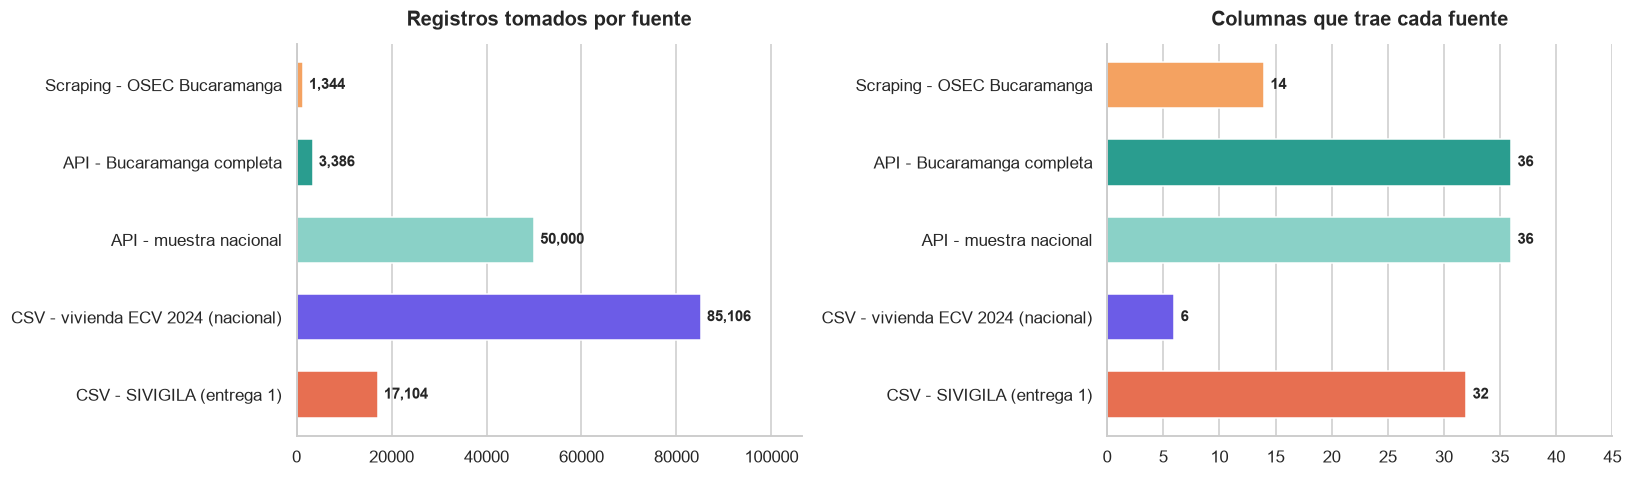

In [51]:
# Gráfica: registros y columnas que aportó cada fuente
colores = [FUENTES["scraping"]["color"], FUENTES["api"]["color"], "#8AD1C7", FUENTES["vivienda"]["color"], FUENTES["sivigila"]["color"]]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, col, titulo in zip(axes, ["registros", "columnas"], ["Registros tomados por fuente", "Columnas que trae cada fuente"]):
    y = np.arange(len(resumen))[::-1]
    valores = resumen[col].values
    b = ax.barh(y, valores, color=colores, height=0.6)
    ax.set_yticks(y, labels=resumen.index)
    ax.bar_label(b, labels=[f"{int(v):,}" for v in valores], padding=4, fontsize=10, fontweight="bold")
    ax.set_xlim(0, max(valores.max(), 1) * 1.25)
    ax.set_title(titulo)
    ax.grid(axis="y", visible=False)
plt.tight_layout()
guardar("01_fuentes_registros_columnas.png")
plt.show()

Lo que se ve: el CSV de vivienda es el que más filas aporta porque se leyó completo (todo el país), pero solo una parte pequeña es de Bucaramanga. La muestra nacional de la API es la segunda fuente más grande y la usamos únicamente para comparar. Las tres fuentes que realmente hablan de Bucaramanga son la API filtrada, SIVIGILA y el scraping del OSEC

Las fuentes no comparten una columna que permita unirlas directamente fila por fila, porque cada una mide algo distinto. Por eso cada una se perfila por separado y al final (Parte 6) definimos por cuál variable se puede cruzar cada par de fuentes

## Parte 2. Fuente 1: scraping del OSEC

### 2.1 Estructura y tipos de datos

Cada fila es una comuna dentro de un boletín, para un delito (violencia intrafamiliar o delitos sexuales) y un bloque (acumulado del año o mes de referencia). Las columnas son:

| Columna | Qué significa |
|---|---|
| `periodo` | Mes del boletín en formato AAAAMM (por ejemplo 202608 = agosto de 2026) |
| `delito` | VIOLENCIA INTRAFAMILIAR o DELITOS SEXUALES |
| `bloque` | ACUMULADO (enero hasta el mes del boletín) o MES (solo el mes del boletín) |
| `comuna` | Nombre de la comuna como viene en el PDF, con su número (por ejemplo "01. NORTE") |
| `casos_anio_anterior` / `casos_anio_actual` | Casos del mismo periodo en el año anterior y en el año del boletín |
| `diferencia` / `variacion_pct` | Diferencia en casos y variación porcentual que calcula el OSEC |
| `anio_anterior` / `anio_actual` | Años de la comparación, calculados a partir del periodo |
| `pagina_pdf`, `url_pdf`, `fecha_extraccion`, `fuente` | Datos de trazabilidad: de dónde salió cada fila |

In [52]:
display(osec.head())
print("\nFicha de columnas:")
display(perfil_columnas(osec))
print("Columnas que llegan como texto pero son números:", parecen_numero(osec, excluir=("url_pdf", "fecha_extraccion")))

,periodo,delito,bloque,comuna,casos_anio_anterior,casos_anio_actual,diferencia,variacion_pct,anio_anterior,anio_actual,pagina_pdf,url_pdf,fecha_extraccion,fuente
0,202505,DELITOS SEXUALES,ACUMULADO,01. NORTE,14,20,6,"42,86",2024,2025,54,https://www.bucaramanga.gov.co/wp-content/uploads/2025/0...,2026-10-13 14:22:28,Scraping_OSEC_Bucaramanga
1,202505,DELITOS SEXUALES,MES,01. NORTE,2,5,3,"150,00",2024,2025,54,https://www.bucaramanga.gov.co/wp-content/uploads/2025/0...,2026-10-13 14:22:28,Scraping_OSEC_Bucaramanga
2,202505,DELITOS SEXUALES,ACUMULADO,02. NORORIENTAL,4,8,4,"100,00",2024,2025,54,https://www.bucaramanga.gov.co/wp-content/uploads/2025/0...,2026-10-13 14:22:28,Scraping_OSEC_Bucaramanga
3,202505,DELITOS SEXUALES,MES,02. NORORIENTAL,2,1,-1,"-50,00",2024,2025,54,https://www.bucaramanga.gov.co/wp-content/uploads/2025/0...,2026-10-13 14:22:28,Scraping_OSEC_Bucaramanga
4,202505,DELITOS SEXUALES,ACUMULADO,03. SAN FRANCISCO,8,10,2,"25,00",2024,2025,54,https://www.bucaramanga.gov.co/wp-content/uploads/2025/0...,2026-10-13 14:22:28,Scraping_OSEC_Bucaramanga



Ficha de columnas:


,tipo,nulos,pct_nulos,distintos,ejemplo
periodo,str,0,0.0,16,202505
delito,str,0,0.0,2,DELITOS SEXUALES
bloque,str,0,0.0,2,ACUMULADO
comuna,str,0,0.0,21,01. NORTE
casos_anio_anterior,str,0,0.0,119,14
casos_anio_actual,str,0,0.0,120,20
diferencia,str,0,0.0,92,6
variacion_pct,str,0,0.0,329,"42,86"
anio_anterior,str,0,0.0,2,2024
anio_actual,str,0,0.0,2,2025


Columnas que llegan como texto pero son números: ['periodo', 'casos_anio_anterior', 'casos_anio_actual', 'diferencia', 'variacion_pct', 'anio_anterior', 'anio_actual', 'pagina_pdf']


In [53]:
# Las cifras vienen escritas al estilo colombiano: punto para miles y coma para decimales ("1.128", "13,95").
# Solo para poder revisarlas aquí se convierten a número en columnas NUEVAS; los datos originales no se tocan.
def a_entero(s):
    return pd.to_numeric(s.astype(str).str.replace(".", "", regex=False), errors="coerce")


def a_decimal(s):
    return pd.to_numeric(s.astype(str).str.replace(".", "", regex=False).str.replace(",", ".", regex=False), errors="coerce")


o = osec.copy()
o["ant"] = a_entero(o["casos_anio_anterior"])
o["act"] = a_entero(o["casos_anio_actual"])
o["dif"] = a_entero(o["diferencia"])
o["var"] = a_decimal(o["variacion_pct"])
o["anio_act"] = a_entero(o["anio_actual"])

for col_original, col_num in [("casos_anio_anterior", "ant"), ("casos_anio_actual", "act"),
                              ("diferencia", "dif"), ("variacion_pct", "var")]:
    malos = int(o[col_num].isna().sum() - o[col_original].isna().sum())
    print(f"{col_original:22s}: valores que no se pudieron leer como número = {malos}")

print("\nValores de 'variacion_pct' con coma decimal (ej.):", list(osec["variacion_pct"].dropna().unique()[:5]))

casos_anio_anterior   : valores que no se pudieron leer como número = 0
casos_anio_actual     : valores que no se pudieron leer como número = 0
diferencia            : valores que no se pudieron leer como número = 0
variacion_pct         : valores que no se pudieron leer como número = 0

Valores de 'variacion_pct' con coma decimal (ej.): ['42,86', '150,00', '100,00', '-50,00', '25,00']


Todo llega como texto, que es lo correcto para la capa cruda, y todas las cifras se pueden convertir a número sin errores. Lo único que hay que cuidar en la transformación es el formato colombiano: la variación usa coma decimal ("13,95"), así que no basta con un `astype(float)`

### 2.2 Valores faltantes

In [54]:
nulos_osec = perfil_columnas(osec)[["nulos", "pct_nulos"]]
print(f"Celdas vacías en toda la tabla: {pct_vacio(osec)}%")
display(nulos_osec[nulos_osec["nulos"] > 0] if (nulos_osec["nulos"] > 0).any() else "Ninguna columna tiene nulos")

# En esta fuente el "sin dato" no aparece como texto, sino como una comuna llamada NO DISPONIBLE
no_disp = o[o["comuna"].str.upper().eq("NO DISPONIBLE")]
print(f"\nFilas de la comuna 'NO DISPONIBLE': {len(no_disp)}")
print("Casos del año actual sin comuna (bloque ACUMULADO, último boletín):")
ultimo = o["periodo"].max()
display(no_disp[(no_disp["periodo"] == ultimo) & (no_disp["bloque"] == "ACUMULADO")][["delito", "casos_anio_anterior", "casos_anio_actual"]])

Celdas vacías en toda la tabla: 0.0%


'Ninguna columna tiene nulos'


Filas de la comuna 'NO DISPONIBLE': 64
Casos del año actual sin comuna (bloque ACUMULADO, último boletín):


,delito,casos_anio_anterior,casos_anio_actual
1300,DELITOS SEXUALES,0,0
1342,VIOLENCIA INTRAFAMILIAR,3,1


No hay celdas vacías: el extractor solo guarda una fila cuando encuentra la comuna con sus 4 cifras completas. La falta de dato en esta fuente aparece de otra forma, como la fila "NO DISPONIBLE", que agrupa los casos que la Policía no pudo ubicar en ninguna comuna. Son pocos casos, pero en la transformación no se deben repartir entre comunas ni borrar: se dejan como una categoría aparte para que los totales de la ciudad cuadren

### 2.3 Duplicados

En esta fuente una fila debería ser única por la combinación `periodo + delito + bloque + comuna`. Si esa combinación se repite, el extractor leyó dos veces la misma tabla

In [55]:
LLAVE_OSEC = ["periodo", "delito", "bloque", "comuna"]
dup_completo = int(osec.duplicated().sum())
dup_llave = int(osec.duplicated(subset=LLAVE_OSEC).sum())
print(f"Filas idénticas en todas las columnas: {dup_completo}")
print(f"Filas repetidas en la llave {LLAVE_OSEC}: {dup_llave}")

control = osec.groupby(["periodo", "delito", "bloque"]).size().unstack(fill_value=0)
print(f"\nFilas por boletín, delito y bloque (deben ser 21 = 17 comunas + 3 corregimientos + NO DISPONIBLE):")
print("¿Todas las combinaciones tienen 21 filas?", bool((control == 21).all().all()))
display(control.head(4))

comunas_distintas = sorted(osec["comuna"].unique())
print(f"Comunas distintas: {len(comunas_distintas)}")
print(comunas_distintas)

Filas idénticas en todas las columnas: 0
Filas repetidas en la llave ['periodo', 'delito', 'bloque', 'comuna']: 0

Filas por boletín, delito y bloque (deben ser 21 = 17 comunas + 3 corregimientos + NO DISPONIBLE):
¿Todas las combinaciones tienen 21 filas? True


bloque                           ACUMULADO  MES
periodo delito                                 
202505  DELITOS SEXUALES                21   21
        VIOLENCIA INTRAFAMILIAR         21   21
202506  DELITOS SEXUALES                21   21
        VIOLENCIA INTRAFAMILIAR         21   21

Comunas distintas: 21
['01. NORTE', '02. NORORIENTAL', '03. SAN FRANCISCO', '04. OCCIDENTAL', '05. GARCIA ROVIRA', '06. LA CONCORDIA', '07. CIUDADELA REAL DE MINAS', '08. SUROCCIDENTE', '09. LA PEDREGOSA', '10. PROVENZA', '11. SUR', '12. CABECERA DEL LLANO', '13. ORIENTAL', '14. MORRORICO', '15. CENTRO', '16. TEJAR', '17. MUTIS', 'CORREGIMIENTO 1', 'CORREGIMIENTO 2', 'CORREGIMIENTO 3', 'NO DISPONIBLE']


No hay duplicados y cada boletín trae exactamente 21 filas por delito y bloque, siempre con los mismos 21 nombres de comuna. Esto quiere decir que el formato del PDF no ha cambiado entre mayo de 2025 y el último boletín. Esta misma revisión la vamos a dejar como expectativa de Great Expectations, porque si la Alcaldía cambia el diseño del boletín, el pipeline debe detenerse antes de cargar datos incompletos

### 2.4 Consistencia interna de las cifras

Además de nulos y duplicados, en una tabla que viene de un PDF hay que revisar que las cifras tengan sentido entre ellas:

- La diferencia debe ser igual a casos del año actual menos casos del año anterior
- La variación debe ser igual a diferencia dividida en casos del año anterior, por 100
- El acumulado de un año no puede bajar de un mes a otro (si en marzo iban 100 casos, en abril no pueden ir 90)

In [56]:
# 1) Diferencia
dif_ok = (o["act"] - o["ant"] == o["dif"])
print(f"Diferencia correcta: {dif_ok.mean() * 100:.1f}% de las filas ({int((~dif_ok).sum())} con error)")

# 2) Variación (solo se puede calcular si el año anterior tiene casos)
con_base = o["ant"] > 0
var_calc = (o["act"] - o["ant"]) / o["ant"] * 100
var_ok = (var_calc - o["var"]).abs() <= 0.01
print(f"Variación correcta (con casos en el año anterior): {var_ok[con_base].mean() * 100:.1f}%")

base_cero = o[(o["ant"] == 0) & (o["act"] > 0)]
print(f"\nFilas con 0 casos el año anterior y casos este año: {len(base_cero)}")
print("Variación que reporta el PDF en esas filas:", sorted(base_cero["variacion_pct"].unique())[:5])

# 3) El acumulado del mismo año no debe bajar de un boletín al siguiente
acum = (o[o["bloque"] == "ACUMULADO"].sort_values("periodo")
        .assign(cambio=lambda d: d.groupby(["delito", "comuna", "anio_act"])["act"].diff()))
bajas = acum[acum["cambio"] < 0]
print(f"\nVeces que el acumulado bajó de un boletín al siguiente: {len(bajas)}")
if len(bajas):
    display(bajas[["periodo", "delito", "comuna", "casos_anio_actual", "cambio"]].head(10))

Diferencia correcta: 100.0% de las filas (0 con error)
Variación correcta (con casos en el año anterior): 100.0%

Filas con 0 casos el año anterior y casos este año: 71
Variación que reporta el PDF en esas filas: ['100,00', '200,00', '300,00', '400,00', '500,00']

Veces que el acumulado bajó de un boletín al siguiente: 34


,periodo,delito,comuna,casos_anio_actual,cambio
302,202508,VIOLENCIA INTRAFAMILIAR,05. GARCIA ROVIRA,158,-37.0
274,202508,DELITOS SEXUALES,12. CABECERA DEL LLANO,13,-1.0
386,202509,VIOLENCIA INTRAFAMILIAR,05. GARCIA ROVIRA,83,-75.0
416,202509,VIOLENCIA INTRAFAMILIAR,CORREGIMIENTO 3,18,-1.0
338,202509,DELITOS SEXUALES,02. NORORIENTAL,9,-1.0
492,202510,VIOLENCIA INTRAFAMILIAR,16. TEJAR,11,-1.0
458,202510,DELITOS SEXUALES,CORREGIMIENTO 3,2,-1.0
450,202510,DELITOS SEXUALES,16. TEJAR,4,-1.0
514,202511,DELITOS SEXUALES,06. LA CONCORDIA,18,-2.0
516,202511,DELITOS SEXUALES,07. CIUDADELA REAL DE MINAS,9,-1.0


Las diferencias y las variaciones que publica el OSEC coinciden con el cálculo, salvo en un caso especial: cuando el año anterior tiene 0 casos la variación matemáticamente no existe (se divide por cero) y el PDF la reporta con un valor fijo. Por eso en la transformación **no vamos a usar la variación del PDF**: la vamos a recalcular nosotros y la dejaremos vacía cuando el año anterior sea 0

Si el acumulado baja de un boletín a otro, no es un error del scraping. El propio boletín advierte que las cifras están "sujetas a variación por ingreso y validación de denuncias en SIEDCO", o sea que la Policía corrige los meses anteriores. Esto nos lleva a la siguiente revisión

### 2.5 Revisiones entre boletines y serie mensual

Cada boletín trae el mes de referencia del año actual y **el mismo mes del año anterior**. Por ejemplo, el boletín de agosto de 2026 trae agosto de 2026 y agosto de 2025. Pero agosto de 2025 ya había salido en su propio boletín (el de agosto de 2025). Si comparamos las dos cifras podemos ver cuánto corrige la Policía sus datos un año después

In [57]:
mes = o[o["bloque"] == "MES"].copy()
mes["anio_ant"] = a_entero(mes["anio_anterior"])
mes["mes_num"] = mes["periodo"].str[4:6]

# Cada fila del bloque MES da dos datos: el mes en el año actual y el mismo mes en el año anterior
serie_larga = pd.concat([
    pd.DataFrame({"delito": mes["delito"], "comuna": mes["comuna"], "periodo_dato": mes["anio_act"].astype(str) + mes["mes_num"],
                  "casos": mes["act"], "publicado_en": mes["periodo"], "tipo": "actual"}),
    pd.DataFrame({"delito": mes["delito"], "comuna": mes["comuna"], "periodo_dato": mes["anio_ant"].astype(str) + mes["mes_num"],
                  "casos": mes["ant"], "publicado_en": mes["periodo"], "tipo": "año anterior"}),
], ignore_index=True)

# Meses que aparecen en dos boletines distintos
rev = serie_larga.pivot_table(index=["delito", "comuna", "periodo_dato"], columns="tipo", values="casos", aggfunc="first").dropna()
rev["correccion"] = rev["año anterior"] - rev["actual"]
print(f"Meses-comuna publicados dos veces (primero como mes actual y un año después como año anterior): {len(rev):,}")
print(f"  Con la misma cifra: {(rev['correccion'] == 0).mean() * 100:.1f}%")
print(f"  Corregidos hacia arriba: {(rev['correccion'] > 0).mean() * 100:.1f}% | hacia abajo: {(rev['correccion'] < 0).mean() * 100:.1f}%")

por_delito = rev.groupby(level="delito")[["actual", "año anterior"]].sum()
por_delito["correccion_pct"] = ((por_delito["año anterior"] / por_delito["actual"] - 1) * 100).round(1)
print("\nTotal de la ciudad en esos meses, primera publicación vs. publicación un año después:")
display(por_delito)

# Serie mensual de la ciudad: para cada mes se usa la cifra del boletín más reciente que lo publicó
serie = (serie_larga.sort_values("publicado_en")
         .drop_duplicates(["delito", "comuna", "periodo_dato"], keep="last")
         .groupby(["periodo_dato", "delito"])["casos"].sum().unstack())
print(f"\nLa serie mensual va de {serie.index.min()} a {serie.index.max()} ({len(serie)} meses)")

Meses-comuna publicados dos veces (primero como mes actual y un año después como año anterior): 168
  Con la misma cifra: 38.1%
  Corregidos hacia arriba: 50.0% | hacia abajo: 11.9%

Total de la ciudad en esos meses, primera publicación vs. publicación un año después:


tipo,actual,año anterior,correccion_pct
delito,,,
DELITOS SEXUALES,110.0,124.0,12.7
VIOLENCIA INTRAFAMILIAR,438.0,570.0,30.1



La serie mensual va de 202405 a 202608 (28 meses)


2026-10-13 15:54:03,902 - [INFO] - matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-13 15:54:03,920 - [INFO] - matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-13 15:54:03,945 - [INFO] - matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-13 15:54:03,950 - [INFO] - matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


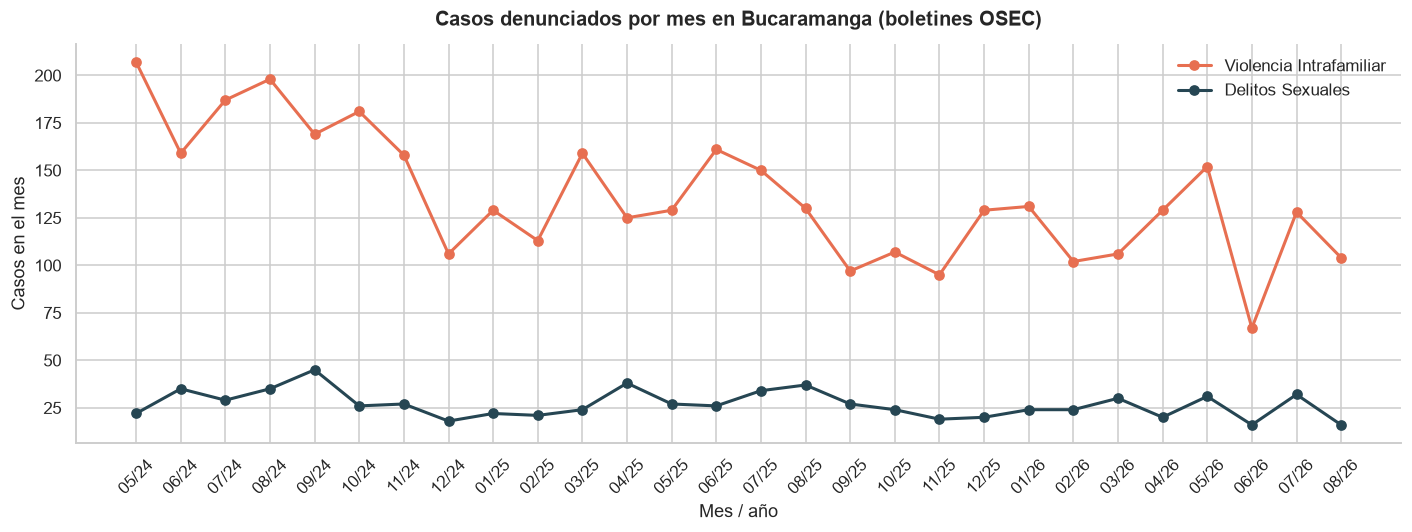

In [58]:
fig, ax = plt.subplots(figsize=(13, 5))
etiquetas = [f"{p[4:]}/{p[2:4]}" for p in serie.index]
for delito, color in [("VIOLENCIA INTRAFAMILIAR", "#E76F51"), ("DELITOS SEXUALES", "#264653")]:
    if delito in serie.columns:
        ax.plot(etiquetas, serie[delito].values, marker="o", lw=2, color=color, label=delito.title())
ax.set_title("Casos denunciados por mes en Bucaramanga (boletines OSEC)")
ax.set_xlabel("Mes / año")
ax.set_ylabel("Casos en el mes")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
guardar("02_osec_serie_mensual.png")
plt.show()

Este hallazgo es importante para el diseño del pipeline. Como la Policía corrige las cifras de meses anteriores, un mismo mes puede tener dos valores distintos según el boletín del que se tome. La regla que adoptamos es **quedarnos siempre con la cifra del boletín más reciente**, porque es la más corregida. Gracias a que cada boletín trae también el año anterior, con 16 boletines podemos reconstruir una serie mensual más larga (desde mayo de 2024)

En la gráfica se ve que la violencia intrafamiliar es varias veces más frecuente que los delitos sexuales en todos los meses, lo que coincide con lo que encontramos en la primera entrega con SIVIGILA (la violencia física era la categoría más grande)

### 2.6 Valores atípicos (outliers)

En esta fuente revisamos dos tipos de valores atípicos:

- **Outliers estadísticos (IQR)** en los casos por comuna, para saber si alguna comuna tiene cifras muy por encima de las demás
- **Variaciones extremas**: porcentajes muy grandes (como +300 %) que pueden asustar en un tablero pero que salen de comparar números muy pequeños (pasar de 1 a 4 casos es +300 %)

In [59]:
ult = o[(o["periodo"] == o["periodo"].max()) & (o["bloque"] == "ACUMULADO")]
filas = []
for delito, g in ult.groupby("delito"):
    r = resumen_iqr(g["act"])
    altas = g.loc[g["act"] > r["lim_sup"], "comuna"].tolist() if r["n"] else []
    filas.append({"delito": delito, "comunas": r["n"], "Q1": r["q1"], "Q3": r["q3"],
                  "límite superior": round(r["lim_sup"], 1), "outliers": r["outliers"], "comunas atípicas": ", ".join(altas)})
print(f"Outliers por IQR en el acumulado del último boletín ({o['periodo'].max()}):")
display(pd.DataFrame(filas).set_index("delito"))

extremas = o[o["var"].abs() >= 100]
print(f"\nFilas con variación de ±100 % o más: {len(extremas)} ({len(extremas) / len(o) * 100:.1f}%)")
print(f"De esas, cuántas tienen 5 casos o menos en el año anterior: {(extremas['ant'] <= 5).mean() * 100:.1f}%")

Outliers por IQR en el acumulado del último boletín (202608):


,comunas,Q1,Q3,límite superior,outliers,comunas atípicas
delito,,,,,,
DELITOS SEXUALES,21,3.0,14.0,30.5,1,01. NORTE
VIOLENCIA INTRAFAMILIAR,21,11.0,83.0,191.0,1,01. NORTE



Filas con variación de ±100 % o más: 326 (24.3%)
De esas, cuántas tienen 5 casos o menos en el año anterior: 91.1%


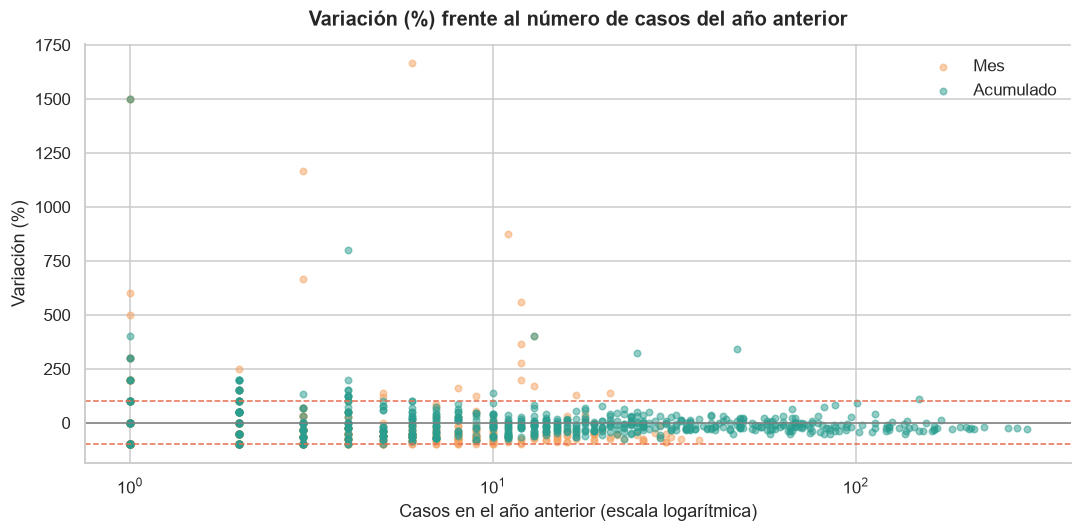

In [60]:
fig, ax = plt.subplots(figsize=(10, 5))
for bloque, color in [("MES", "#F4A261"), ("ACUMULADO", "#2A9D8F")]:
    d = o[(o["bloque"] == bloque) & (o["ant"] > 0)]
    ax.scatter(d["ant"], d["var"], s=18, alpha=0.5, color=color, label=bloque.title())
ax.axhline(0, color="gray", lw=1)
ax.axhline(100, color="#E76F51", lw=1, ls="--")
ax.axhline(-100, color="#E76F51", lw=1, ls="--")
ax.set_xscale("log")
ax.set_title("Variación (%) frente al número de casos del año anterior")
ax.set_xlabel("Casos en el año anterior (escala logarítmica)")
ax.set_ylabel("Variación (%)")
ax.legend()
plt.tight_layout()
guardar("03_osec_variacion_vs_base.png")
plt.show()

La gráfica muestra la forma típica de "embudo": cuando la base es pequeña (izquierda) las variaciones son enormes, y cuando la base es grande (derecha) las variaciones se acercan a cero. Es decir, las variaciones extremas no son errores, son un efecto de los números pequeños, sobre todo en el bloque MES y en comunas con pocos casos

Por eso en los tableros **no vamos a mostrar la variación porcentual sola**: siempre irá acompañada del número de casos, y para comparar comunas usaremos los casos absolutos o el acumulado del año, que es más estable que el dato de un solo mes. Las comunas que salen como outliers por IQR sí son reales (son las comunas más grandes y pobladas) y son justamente las que queremos identificar para priorizar

### 2.7 Variables clave y estadísticas básicas

In [61]:
print("Variables clave del scraping: periodo, delito, bloque, comuna y casos (año actual y anterior)\n")
print(f"Boletines: {o['periodo'].nunique()} (de {o['periodo'].min()} a {o['periodo'].max()})")
print(f"Delitos: {', '.join(sorted(o['delito'].unique()))}")
print(f"Comunas y corregimientos: {o['comuna'].nunique()}\n")

print(f"Estadísticas de los casos por comuna en el acumulado del último boletín ({o['periodo'].max()}):")
display(ult.groupby("delito")["act"].describe().round(1))

totales = ult.groupby("delito")[["ant", "act"]].sum()
totales["variacion_pct"] = ((totales["act"] / totales["ant"] - 1) * 100).round(2)
print("Total de la ciudad (suma de las 21 filas), acumulado del año:")
display(totales.rename(columns={"ant": f"casos {int(ult['anio_act'].iloc[0]) - 1}", "act": f"casos {int(ult['anio_act'].iloc[0])}"}))

Variables clave del scraping: periodo, delito, bloque, comuna y casos (año actual y anterior)

Boletines: 16 (de 202505 a 202608)
Delitos: DELITOS SEXUALES, VIOLENCIA INTRAFAMILIAR
Comunas y corregimientos: 21

Estadísticas de los casos por comuna en el acumulado del último boletín (202608):


,count,mean,std,min,25%,50%,75%,max
delito,,,,,,,,
DELITOS SEXUALES,21.0,10.8,9.3,0.0,3.0,12.0,14.0,32.0
VIOLENCIA INTRAFAMILIAR,21.0,53.7,49.2,1.0,11.0,45.0,83.0,196.0


Total de la ciudad (suma de las 21 filas), acumulado del año:


,casos 2025,casos 2026,variacion_pct
delito,,,
DELITOS SEXUALES,256,227,-11.33
VIOLENCIA INTRAFAMILIAR,1085,1128,3.96


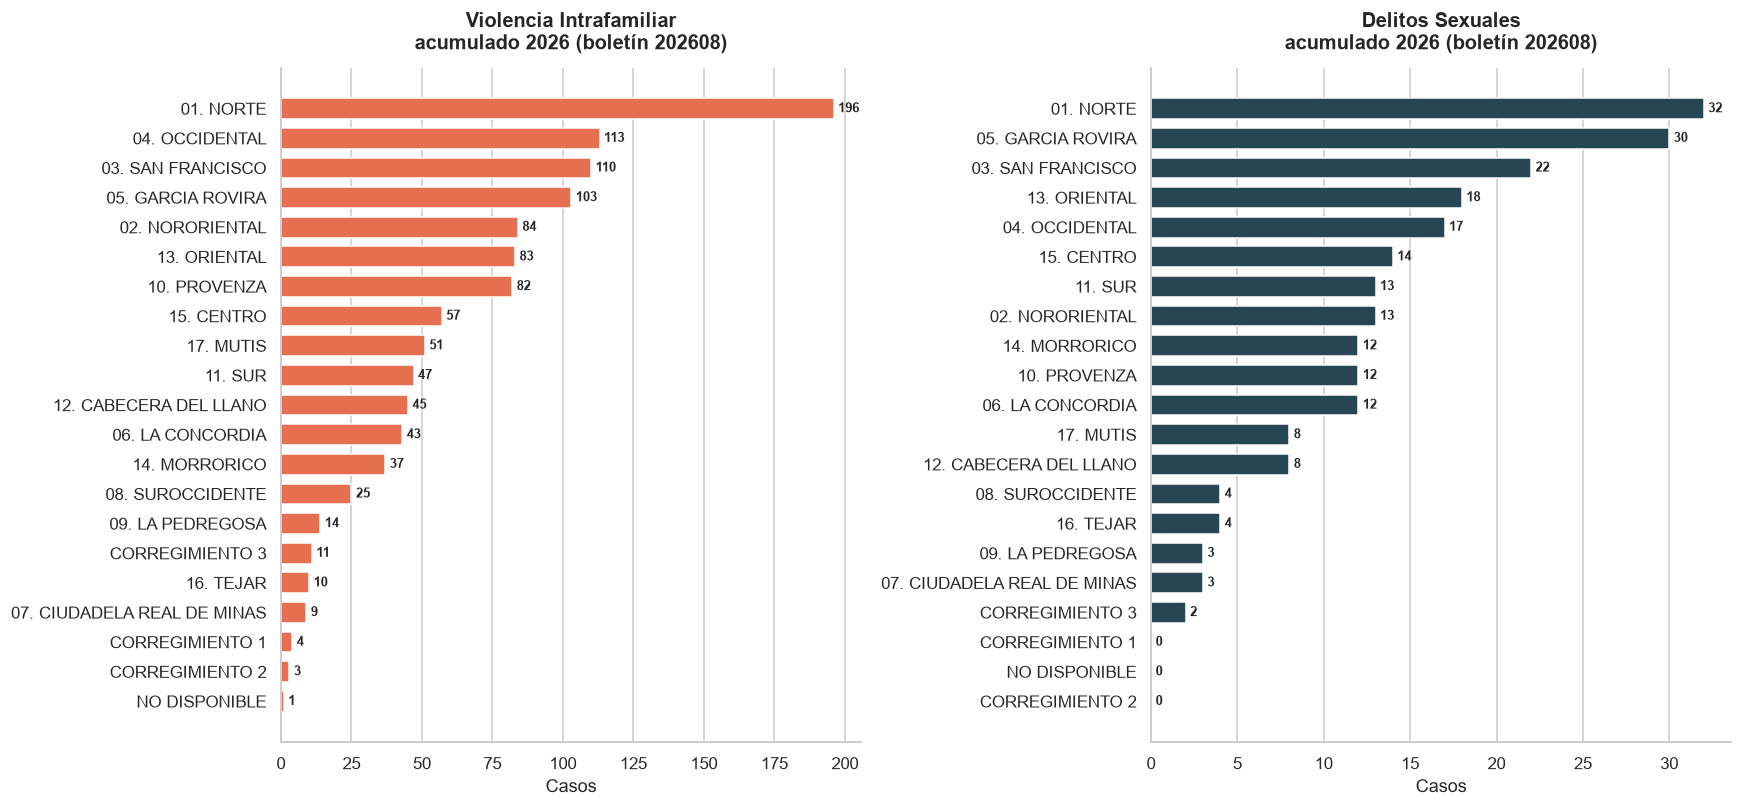

In [62]:
# Ranking de comunas en el acumulado del último boletín, por delito
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
for ax, (delito, color) in zip(axes, [("VIOLENCIA INTRAFAMILIAR", "#E76F51"), ("DELITOS SEXUALES", "#264653")]):
    d = ult[ult["delito"] == delito].sort_values("act", ascending=True)
    b = ax.barh(d["comuna"], d["act"], color=color, height=0.7)
    ax.bar_label(b, padding=3, fontsize=8.5, fontweight="bold")
    ax.set_title(f"{delito.title()}\nacumulado {int(d['anio_act'].iloc[0])} (boletín {o['periodo'].max()})")
    ax.set_xlabel("Casos")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
guardar("04_osec_ranking_comunas.png")
plt.show()

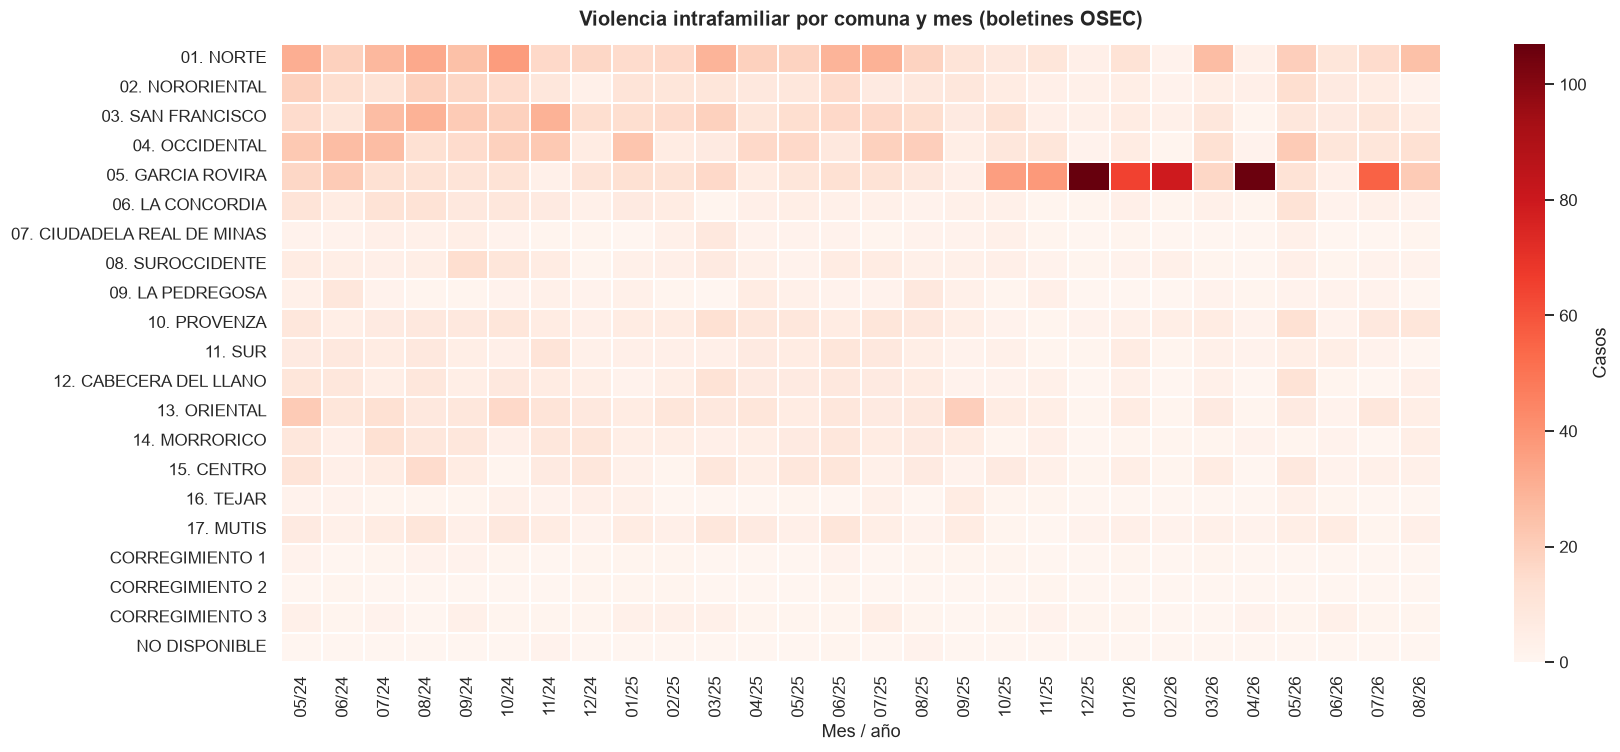

In [63]:
# Mapa de calor: violencia intrafamiliar por comuna y mes (cifra del boletín más reciente)
vif_mes = (serie_larga[serie_larga["delito"] == "VIOLENCIA INTRAFAMILIAR"]
           .sort_values("publicado_en")
           .drop_duplicates(["comuna", "periodo_dato"], keep="last")
           .pivot_table(index="comuna", columns="periodo_dato", values="casos", aggfunc="sum"))
vif_mes.columns = [f"{c[4:]}/{c[2:4]}" for c in vif_mes.columns]
plt.figure(figsize=(16, 7))
sns.heatmap(vif_mes, cmap="Reds", linewidths=0.3, cbar_kws={"label": "Casos"})
plt.title("Violencia intrafamiliar por comuna y mes (boletines OSEC)")
plt.xlabel("Mes / año")
plt.ylabel("")
plt.tight_layout()
guardar("05_osec_vif_comuna_mes.png")
plt.show()

### 2.8 Observaciones del scraping

- La extracción es completa y estable: 16 boletines, 21 filas por delito y bloque en todos, sin nulos ni duplicados
- Todo llega como texto y con formato colombiano (coma decimal). Hay que convertirlo con cuidado en la transformación
- La comuna viene como "número. NOMBRE" (por ejemplo "01. NORTE"), lo que es muy útil para unir con otras fuentes por el **número** de comuna, que es más confiable que el nombre escrito
- Hay una categoría "NO DISPONIBLE" para los casos sin ubicación y tres corregimientos que no son comunas urbanas
- La variación porcentual del PDF no sirve cuando el año anterior tiene 0 casos y es engañosa con bases pequeñas. Se recalcula y se interpreta con cuidado
- Las cifras de un mes cambian entre boletines porque la Policía corrige sus registros. Se debe usar la cifra del boletín más reciente
- El acumulado y el mes son dos vistas del mismo dato, así que **no se deben sumar entre bloques**
- Esta fuente cuenta denuncias de toda la población de cada comuna (no separa por sexo en estas tablas). Se compara con las otras fuentes, no se suma con ellas

## Parte 3. Fuente 2: API de Medicina Legal

Cada fila es un caso de violencia intrafamiliar valorado por Medicina Legal, con datos de la víctima, del hecho y del presunto agresor. El análisis se hace sobre **todos los casos de Bucaramanga**; la muestra nacional se usa solo al final (3.8) para comparar

### 3.1 Estructura general

In [64]:
print(f"Bucaramanga: {len(api_bga):,} registros | {api_bga.shape[1]} columnas")
if TOTAL_API_BGA:
    print(f"¿Llegaron todos los casos de la ciudad? {len(api_bga) == TOTAL_API_BGA} ({len(api_bga):,} de {TOTAL_API_BGA:,})")
print("Municipios en la consulta filtrada:", api_bga["municipio_del_hecho_dane"].unique().tolist())
print("\nColumnas:")
print(", ".join(api_bga.columns))
display(api_bga.head(3))

Bucaramanga: 3,386 registros | 36 columnas
¿Llegaron todos los casos de la ciudad? True (3,386 de 3,386)
Municipios en la consulta filtrada: ['Bucaramanga']

Columnas:
id, a_o_del_hecho, sexo_de_la_victima, grupo_de_edad_quinquenal, grupo_mayor_menor_de_edad, grupo_de_edad_judicial, ciclo_vital, pais_de_nacimiento, escolaridad, estado_civil, tipo_de_discapacidad, pertenencia_etnica, orientacion_sexual, identidad_de_genero, transgenero, pertenencia_grupal, mes_del_hecho, dia_del_hecho, rango_de_hora_del_hecho_x_3_horas, codigo_dane_municipio, municipio_del_hecho_dane, departamento_del_hecho_dane, codigo_dane_departamento, localidad_del_hecho, zona_del_hecho, escenario_del_hecho, actividad_durante_el_hecho, circunstancia_del_hecho_detallada, contexto_del_hecho, mecanismo_causal_de_la_lesion_no_fatal, diagnostico_topografico_de_la_lesion_no_fatal, sexo_del_agresor, presunto_agresor_detallado, factor_desencadenante_de_la_agresion, dias_de_incapacidad_medicolegal, pueblo_indigena


,id,a_o_del_hecho,sexo_de_la_victima,grupo_de_edad_quinquenal,grupo_mayor_menor_de_edad,grupo_de_edad_judicial,ciclo_vital,pais_de_nacimiento,escolaridad,estado_civil,tipo_de_discapacidad,pertenencia_etnica,orientacion_sexual,identidad_de_genero,transgenero,pertenencia_grupal,mes_del_hecho,dia_del_hecho,rango_de_hora_del_hecho_x_3_horas,codigo_dane_municipio,municipio_del_hecho_dane,departamento_del_hecho_dane,codigo_dane_departamento,localidad_del_hecho,zona_del_hecho,escenario_del_hecho,actividad_durante_el_hecho,circunstancia_del_hecho_detallada,contexto_del_hecho,mecanismo_causal_de_la_lesion_no_fatal,diagnostico_topografico_de_la_lesion_no_fatal,sexo_del_agresor,presunto_agresor_detallado,factor_desencadenante_de_la_agresion,dias_de_incapacidad_medicolegal,pueblo_indigena
0,100006,2018,Hombre,(15 a 17),a) Menores de Edad (<18 años),(14 a 17),(12 a 17) Adolescencia,Colombia,Educación básica secundaria o secundaria baja,Soltero (a),Ninguna,Sin pertenencia étnica,Heterosexual,No Sabe / No Informa,No Sabe / No Informa,Ninguno,agosto,domingo,(18:00 a 20:59),68001,Bucaramanga,Santander,68,Sin información,Cabecera municipal,Vivienda,Actividades vitales o relacionadas con el cuidado personal,"Violencia contra niños, niñas y adolescentes","3 Lesiones no Fatales contra Niños, Niñas y Adolescentes...",Contundente,Politraumatismo,Hombre,Padre,"Intolerancia, machismo",1 a 30,No aplica
1,100007,2018,Mujer,(10 a 14),a) Menores de Edad (<18 años),(10 a 13),(12 a 17) Adolescencia,Colombia,Educación básica primaria,Soltero (a),Ninguna,Sin pertenencia étnica,Heterosexual,No Sabe / No Informa,No Sabe / No Informa,Ninguno,agosto,domingo,(18:00 a 20:59),68001,Bucaramanga,Santander,68,Sin información,Cabecera municipal,Vivienda,Actividades vitales o relacionadas con el cuidado personal,"Violencia contra niños, niñas y adolescentes","3 Lesiones no Fatales contra Niños, Niñas y Adolescentes...",Contundente,Politraumatismo,Hombre,Padre,"Intolerancia, machismo",1 a 30,No aplica
2,100284,2018,Hombre,(20 a 24),b) Mayores de Edad (>18 años),(20 a 24),(18 a 28) Juventud,Colombia,Educación básica secundaria o secundaria baja,Soltero (a),Ninguna,Sin información,Heterosexual,No Sabe / No Informa,No Sabe / No Informa,Ninguno,septiembre,domingo,(09:00 a 11:59),68001,Bucaramanga,Santander,68,Sin información,Cabecera municipal,Vía Pública,Otra,Violencia entre otros familiares,4 Lesiones no Fatales por Violencia entre otros Familiares,Contundente,Politraumatismo,Hombre,Tío (a),Alcoholismo / drogadicción,1 a 30,No aplica


### 3.2 Tipos de datos

In [65]:
display(api_bga.dtypes.astype(str).value_counts().rename("columnas").to_frame())
display(perfil_columnas(api_bga))
print("Columnas que llegan como texto pero parecen números:", parecen_numero(api_bga))

,columnas
str,36


,tipo,nulos,pct_nulos,distintos,ejemplo
id,str,0,0.0,3386,100006
a_o_del_hecho,str,0,0.0,10,2018
sexo_de_la_victima,str,0,0.0,2,Hombre
grupo_de_edad_quinquenal,str,0,0.0,18,(15 a 17)
grupo_mayor_menor_de_edad,str,0,0.0,4,a) Menores de Edad (<18 años)
grupo_de_edad_judicial,str,0,0.0,18,(14 a 17)
ciclo_vital,str,0,0.0,6,(12 a 17) Adolescencia
pais_de_nacimiento,str,0,0.0,4,Colombia
escolaridad,str,0,0.0,17,Educación básica secundaria o secundaria baja
estado_civil,str,0,0.0,8,Soltero (a)


Columnas que llegan como texto pero parecen números: ['id', 'a_o_del_hecho', 'codigo_dane_municipio', 'codigo_dane_departamento']


Todas las columnas llegan como texto, incluso el año, los códigos DANE y los días de incapacidad, porque la API de Socrata devuelve todas las cifras entre comillas (en los metadatos del conjunto las 36 columnas están declaradas como `text`). En la transformación hay que convertir a número solo las columnas que de verdad son números (el año) y dejar los códigos DANE como texto, porque si se vuelven número pierden el cero inicial

### 3.3 Valores faltantes

Aquí hay dos tipos de faltantes: los nulos reales (campos que Socrata no envió) y los textos que en la práctica significan "no hay dato", como "Sin información" o "No Sabe / No Informa". Pandas no cuenta los segundos como nulos, así que los contamos aparte

Columnas con al menos un nulo real: 0 de 36
Celdas vacías en toda la tabla: 0.0%

Columnas con valores tipo 'sin información': 20


,valores_sin_dato,pct
columna,,
transgenero,3386,100.00
localidad_del_hecho,3386,100.00
pueblo_indigena,3115,92.00
identidad_de_genero,2694,79.56
pertenencia_etnica,1569,46.34
orientacion_sexual,1136,33.55
pertenencia_grupal,531,15.68
mecanismo_causal_de_la_lesion_no_fatal,514,15.18
diagnostico_topografico_de_la_lesion_no_fatal,477,14.09


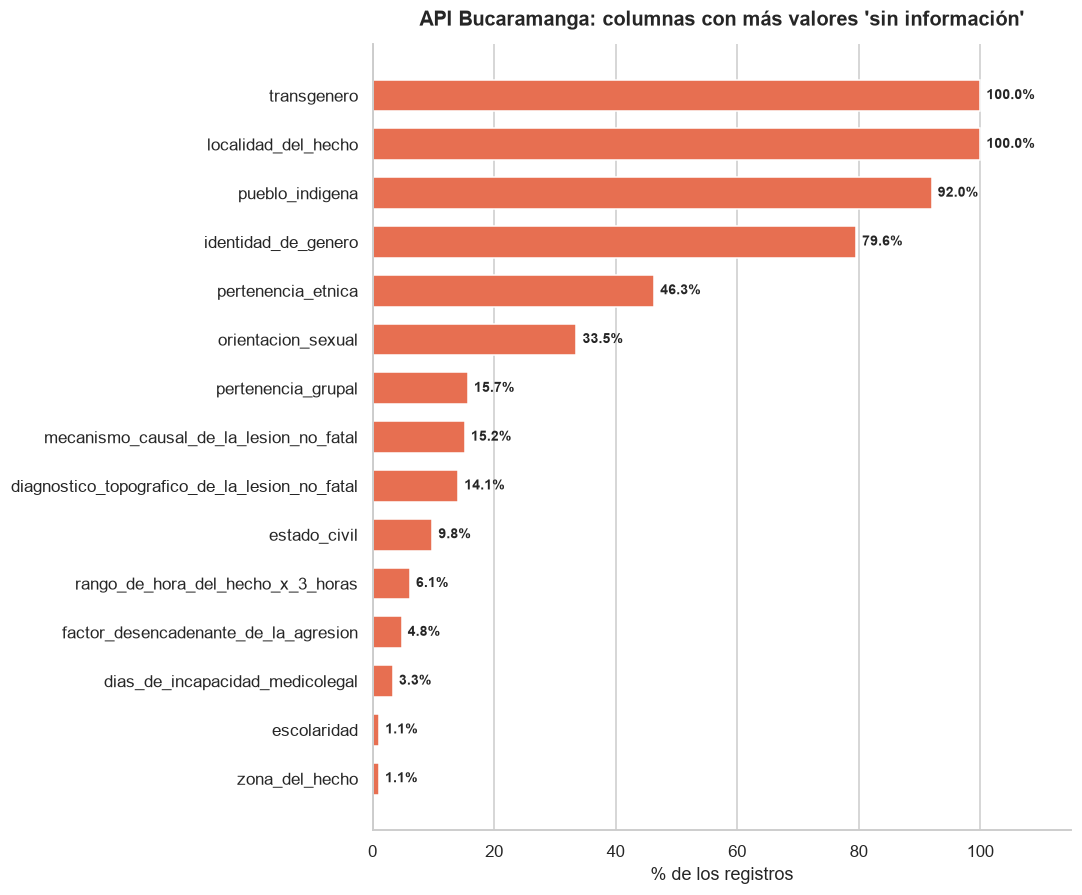

In [66]:
nulos_api = perfil_columnas(api_bga)[["nulos", "pct_nulos"]].sort_values("pct_nulos", ascending=False)
print(f"Columnas con al menos un nulo real: {int((nulos_api['nulos'] > 0).sum())} de {api_bga.shape[1]}")
print(f"Celdas vacías en toda la tabla: {pct_vacio(api_bga)}%")
if (nulos_api["nulos"] > 0).any():
    display(nulos_api[nulos_api["nulos"] > 0])

sin_dato_api = contar_sin_dato(api_bga, excluir=("id",))
top = sin_dato_api[sin_dato_api["valores_sin_dato"] > 0].head(15)
print(f"\nColumnas con valores tipo 'sin información': {int((sin_dato_api['valores_sin_dato'] > 0).sum())}")
display(top)

if len(top):
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(top) + 2))
    y = np.arange(len(top))[::-1]
    b = ax.barh(y, top["pct"], color="#E76F51", height=0.65)
    ax.set_yticks(y, labels=top.index)
    ax.bar_label(b, labels=[f"{p:.1f}%" for p in top["pct"]], padding=4, fontsize=9, fontweight="bold")
    ax.set_xlim(0, 115)
    ax.set_title("API Bucaramanga: columnas con más valores 'sin información'")
    ax.set_xlabel("% de los registros")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    guardar("06_api_sin_informacion.png")
    plt.show()

Casi no hay nulos reales, pero sí muchos textos de "sin dato". Algunas columnas los tienen en casi todos los registros (por ejemplo identidad de género, transgénero, pueblo indígena o pertenencia grupal). Una columna que está vacía en más del 90 % de los casos no aporta información para el análisis, así que esas columnas **no pasan al modelo**. En las columnas que sí usamos (agresor, escenario, hora, ciclo vital), los textos de "sin dato" se unifican en un solo valor, `NO REPORTADO`, que es el que ya usa el modelo de la primera entrega

### 3.4 Duplicados

La columna `id` es única para cada registro, así que si la incluimos nunca saldría un duplicado. Por eso la excluimos al buscar filas repetidas

In [67]:
cols_sin_id = [c for c in api_bga.columns if c != "id"]
print(f"id es único: {api_bga['id'].is_unique}")
dup_api = int(api_bga.duplicated(subset=cols_sin_id).sum())
print(f"Filas repetidas sin contar el id: {dup_api:,} ({dup_api / len(api_bga) * 100:.2f}%)")
if dup_api:
    display(api_bga[api_bga.duplicated(subset=cols_sin_id, keep=False)].sort_values(cols_sin_id[:5]).head(6))
print("\nLos datos están anonimizados: dos casos distintos pueden tener exactamente los mismos atributos")
print("(misma edad, mismo mes, mismo agresor...). Una fila repetida es una alerta, no un error seguro")

id es único: True
Filas repetidas sin contar el id: 0 (0.00%)

Los datos están anonimizados: dos casos distintos pueden tener exactamente los mismos atributos
(misma edad, mismo mes, mismo agresor...). Una fila repetida es una alerta, no un error seguro


Decidimos **no borrar** las filas repetidas. Como cada una tiene un `id` distinto y la fuente no tiene nombre ni documento de la víctima, no hay forma de saber si son el mismo caso o dos casos parecidos (por ejemplo, dos hermanos agredidos por la misma persona el mismo día). Borrarlas podría quitar casos reales. Lo que sí haremos es usar el `id` como llave única y validar que no se repita

### 3.5 Formatos de la hora y de los códigos DANE

In [68]:
from etl.turno import diagnosticar_formatos, calcular_turno, TURNOS_VALIDOS

C_HORA = "rango_de_hora_del_hecho_x_3_horas"
print("Formatos de la hora en la API (Bucaramanga):")
display(diagnosticar_formatos(api_bga[C_HORA]))

# Vista previa: a qué turno quedaría cada rango con la función que ya usa el pipeline
previa = api_bga[C_HORA].map(calcular_turno)
print("Así quedarían los turnos con etl/turno.py (solo vista previa, no se modifica nada):")
display(tabla_frecuencias(previa))
print(pd.crosstab(api_bga[C_HORA], previa).to_string())

Formatos de la hora en la API (Bucaramanga):


,filas,valores_distintos,max_hora,ejemplos
formato,,,,
rango,3178,8,NaN,"[(18:00 a 20:59), (09:00 a 11:59), (15:00 a 17:59)]"
texto,208,1,NaN,[Sin información]


Así quedarían los turnos con etl/turno.py (solo vista previa, no se modifica nada):


,casos,pct
rango_de_hora_del_hecho_x_3_horas,,
TARDE,1695,50.1
MAÑANA,815,24.1
NOCHE,668,19.7
NO REPORTADO,208,6.1


rango_de_hora_del_hecho_x_3_horas  MAÑANA  NO REPORTADO  NOCHE  TARDE
rango_de_hora_del_hecho_x_3_horas                                    
(00:00 a 02:59)                         0             0     87      0
(03:00 a 05:59)                         0             0     77      0
(06:00 a 08:59)                       279             0      0      0
(09:00 a 11:59)                       536             0      0      0
(12:00 a 14:59)                         0             0      0    468
(15:00 a 17:59)                         0             0      0    536
(18:00 a 20:59)                         0             0      0    691
(21:00 a 23:59)                         0             0    504      0
Sin información                         0           208      0      0


In [69]:
for nombre, df_ in [("Bucaramanga", api_bga), ("Muestra nacional", api_nal)]:
    if not len(df_):
        continue
    mun = df_["codigo_dane_municipio"].dropna().astype(str)
    dep = df_["codigo_dane_departamento"].dropna().astype(str)
    print(f"--- {nombre} ---")
    print("Largo de codigo_dane_municipio (lo normal son 5 dígitos):", mun.str.len().value_counts().sort_index().to_dict())
    print("Largo de codigo_dane_departamento (lo normal son 2 dígitos):", dep.str.len().value_counts().sort_index().to_dict())
    coincide = (mun.str.zfill(5).str[:2] == df_.loc[mun.index, "codigo_dane_departamento"].astype(str).str.zfill(2))
    print(f"Los 2 primeros dígitos del municipio coinciden con el departamento: {coincide.mean() * 100:.2f}%\n")

--- Bucaramanga ---
Largo de codigo_dane_municipio (lo normal son 5 dígitos): {5: 3386}
Largo de codigo_dane_departamento (lo normal son 2 dígitos): {2: 3386}
Los 2 primeros dígitos del municipio coinciden con el departamento: 100.00%

--- Muestra nacional ---
Largo de codigo_dane_municipio (lo normal son 5 dígitos): {3: 5, 4: 8643, 5: 41352}
Largo de codigo_dane_departamento (lo normal son 2 dígitos): {1: 8643, 2: 41352, 3: 5}
Los 2 primeros dígitos del municipio coinciden con el departamento: 99.99%



La hora no viene exacta sino en **rangos de 3 horas**, por ejemplo "(18:00 a 20:59)", o como "Sin información". La función `calcular_turno` de la primera entrega ya sabe leer estos rangos: asigna el turno que cubre la mayor parte del rango (al menos 2 de las 3 horas). Esto permite comparar la API con SIVIGILA por turno (mañana, tarde, noche) aunque las dos fuentes escriban la hora de forma distinta

Con los códigos DANE, Bucaramanga no tiene problema (68001 tiene 5 dígitos). En la muestra nacional sí aparece el problema que ya habíamos visto: los departamentos con código de un dígito (por ejemplo Antioquia, 05) pierden el cero inicial y quedan como "5001" en lugar de "05001". La regla es completar con ceros (`zfill(5)` y `zfill(2)`) y guardar el código como texto

### 3.6 Valores atípicos y fuera de rango

En esta fuente casi todas las variables son categorías. La única variable numérica es el **año del hecho**. Los **días de incapacidad médico legal** (los días que Medicina Legal dictamina que la víctima no puede realizar sus actividades por las lesiones) se publican **agrupados en rangos** ("1 a 30", "31 a 90", "Más de 90", "Cero días"), por lo que se analizan como una categoría ordenada y no con estadísticas numéricas. Se revisa:

- Outliers y rango lógico del año: debe estar entre 2015 y 2024, que es el periodo que declara la ficha del conjunto
- Cómo se escriben los días de incapacidad y cuántos casos caen en los rangos más graves, que en una variable agrupada cumplen el papel de los valores extremos
- Categorías raras (5 apariciones o menos) en las variables de texto

In [70]:
anio_api = pd.to_numeric(api_bga["a_o_del_hecho"], errors="coerce")
r_anio = resumen_iqr(anio_api)
print("Año del hecho:")
print(f"  no numéricos: {int(anio_api.isna().sum())} | fuera de 2015-2024: {int((~anio_api.between(2015, 2024)).sum())}")
print(f"  rango: {int(anio_api.min())} a {int(anio_api.max())} | outliers por IQR: {r_anio['outliers']}")

C_INC = "dias_de_incapacidad_medicolegal"
if C_INC in api_bga.columns:
    print("\nDías de incapacidad: valores tal como los publica la fuente")
    display(tabla_frecuencias(api_bga[C_INC]))

Año del hecho:
  no numéricos: 0 | fuera de 2015-2024: 0
  rango: 2015 a 2024 | outliers por IQR: 0

Días de incapacidad: valores tal como los publica la fuente


,casos,pct
dias_de_incapacidad_medicolegal,,
1 a 30,2794,82.5
Cero días y Sin información,158,4.7
Cero días,124,3.7
Sin información,113,3.3
31 a 90,77,2.3
Sin días de incapacidad,63,1.9
Cero días y sin información,55,1.6
Más de 90,2,0.1


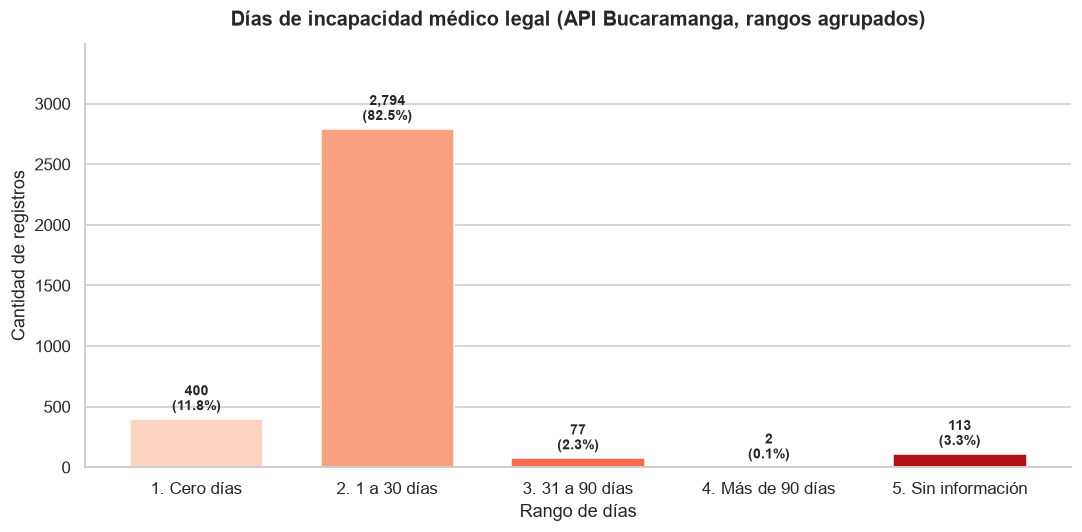

Casos con más de 30 días de incapacidad (los más graves): 79 (2.3%)

Categorías raras (5 veces o menos):


,categorias_total,categorias_raras,registros_en_raras,ejemplos
columna,,,,
escenario_del_hecho,40,26,56,"Oficinas y/o edificios d..., Establecimientos de expe......"
pertenencia_grupal,22,13,27,"Sector social LGBT, Persona privada de la li..., Persona..."
circunstancia_del_hecho_detallada,11,5,18,"Abandono, Embriaguez (alcohólica y..., Económicas"
actividad_durante_el_hecho,17,5,12,"Actividades relacionadas..., Actividades relacionadas......"
presunto_agresor_detallado,31,5,14,"Suegro(a), Profesor (a), Abuelo(a)"
escolaridad,17,4,8,"Especialización, Maestrí..., Universitario, Maestría"
tipo_de_discapacidad,6,4,6,"Visual, Siquica, Mental"
mecanismo_causal_de_la_lesion_no_fatal,12,4,15,"Biodinámico, Proyectil de arma de fue..., Tóxico"
identidad_de_genero,8,3,4,"Transgénero, Travesti, Transexual"


In [71]:
if C_INC in api_bga.columns:
    # Solo para la gráfica se agrupan las distintas formas de escribir el mismo rango
    def grupo_incapacidad(v):
        t = sin_tildes(v) if pd.notna(v) else "SIN INFORMACION"
        if "MAS DE 90" in t:
            return "4. Más de 90 días"
        if "31 A 90" in t:
            return "3. 31 a 90 días"
        if "1 A 30" in t:
            return "2. 1 a 30 días"
        if "CERO" in t or "SIN DIAS" in t:
            return "1. Cero días"
        return "5. Sin información"

    grupos_inc = api_bga[C_INC].map(grupo_incapacidad).value_counts().sort_index()
    barras_verticales(grupos_inc, "Días de incapacidad médico legal (API Bucaramanga, rangos agrupados)",
                      "Rango de días", "07_api_dias_incapacidad.png", color=sns.color_palette("Reds", len(grupos_inc)))
    graves = grupos_inc.filter(like="Más de 90").sum() + grupos_inc.filter(like="31 a 90").sum()
    print(f"Casos con más de 30 días de incapacidad (los más graves): {int(graves)} ({graves / len(api_bga) * 100:.1f}%)")

columnas_texto = [c for c in api_bga.columns if c not in ("id", "a_o_del_hecho", C_INC, "codigo_dane_municipio", "codigo_dane_departamento")]
print("\nCategorías raras (5 veces o menos):")
display(categorias_raras(api_bga, columnas_texto).head(12))

El año no presenta problemas. Los días de incapacidad se publican en **rangos** y el mismo rango aparece escrito de varias formas ("Cero días y Sin información" y "Cero días y sin información"), por eso no se calculan promedios ni cuartiles. En la transformación esta variable se convierte en una categoría ordenada de 5 niveles: cero días, 1 a 30, 31 a 90, más de 90 y sin información. Los casos con más de 30 días son pocos, pero son los más graves, así que **no se eliminan**: son justamente los casos que interesa identificar

Las categorías raras son en su mayoría categorías poco comunes pero válidas (algunos escenarios o tipos de agresor), por lo que se conservan. Además, **una misma categoría aparece escrita de varias formas**: "Hermano (a)" y "Hermano(a)", "Vía Pública" y "Vía pública", "Otros familiares civiles o consanguíneos" con y sin tilde, y el mes del hecho en minúscula ("febrero") y en mayúscula ("Febrero"). En la transformación todo se pasa a mayúsculas, sin tildes y sin espacios antes del paréntesis, para que cada categoría quede escrita de una sola forma

### 3.7 Variables clave, estadísticas básicas y gráficas

Las variables clave de la API para nuestras preguntas son: el año, el sexo de la víctima, el ciclo vital, el tipo de violencia (circunstancia del hecho), el presunto agresor, el escenario y la hora. Como el proyecto se enfoca en violencia contra las mujeres, después de ver la distribución por sexo las gráficas se hacen solo con víctimas mujeres

In [72]:
C_ANIO, C_SEXO, C_CICLO = "a_o_del_hecho", "sexo_de_la_victima", "ciclo_vital"
C_AGRESOR, C_TIPO, C_ESC = "presunto_agresor_detallado", "circunstancia_del_hecho_detallada", "escenario_del_hecho"
VARIABLES_CLAVE = [C_ANIO, C_SEXO, C_CICLO, C_TIPO, C_AGRESOR, C_ESC, C_HORA]

filas = []
for c in VARIABLES_CLAVE:
    if c in api_bga.columns:
        vc = api_bga[c].value_counts()
        filas.append({"variable": c, "categorias": int(vc.size), "mas_frecuente": corto(vc.index[0], 40),
                      "casos": int(vc.iloc[0]), "pct": round(vc.iloc[0] / len(api_bga) * 100, 1),
                      "sin_dato_pct": sin_dato_api.loc[c, "pct"] if c in sin_dato_api.index else 0})
claves_api = pd.DataFrame(filas).set_index("variable")
display(claves_api)

mujeres_api = api_bga[api_bga[C_SEXO] == "Mujer"]
print(f"Víctimas mujeres en Bucaramanga: {len(mujeres_api):,} ({len(mujeres_api) / len(api_bga) * 100:.1f}% de los casos)")

casos_pareja = api_bga[C_AGRESOR].str.contains("pareja|compa|espos|novi", case=False, na=False).sum()
print(f"Casos con agresor pareja, expareja, esposo(a) o novio(a): {casos_pareja}")
if "contexto_del_hecho" in api_bga.columns:
    print("Contextos que incluye este conjunto:")
    display(tabla_frecuencias(api_bga["contexto_del_hecho"]))

,categorias,mas_frecuente,casos,pct,sin_dato_pct
variable,,,,,
a_o_del_hecho,10,2015,469,13.9,0.00
sexo_de_la_victima,2,Mujer,1936,57.2,0.00
ciclo_vital,6,(29 a 59) Adultez,1447,42.7,0.00
circunstancia_del_hecho_detallada,11,Violencia entre otros familiares,2002,59.1,0.00
presunto_agresor_detallado,31,Hermano (a),662,19.6,0.32
escenario_del_hecho,40,Vivienda,2473,73.0,0.86
rango_de_hora_del_hecho_x_3_horas,9,(18:00 a 20:59),691,20.4,6.14


Víctimas mujeres en Bucaramanga: 1,936 (57.2% de los casos)
Casos con agresor pareja, expareja, esposo(a) o novio(a): 0
Contextos que incluye este conjunto:


,casos,pct
contexto_del_hecho,,
4 Lesiones no Fatales por Violencia entre otros Familiares,2170,64.1
"3 Lesiones no Fatales contra Niños, Niñas y Adolescentes por Violencia Intrafamiliar",909,26.8
5 Lesiones no Fatales contra el Adulto Mayor por Violencia Intrafamiliar,307,9.1


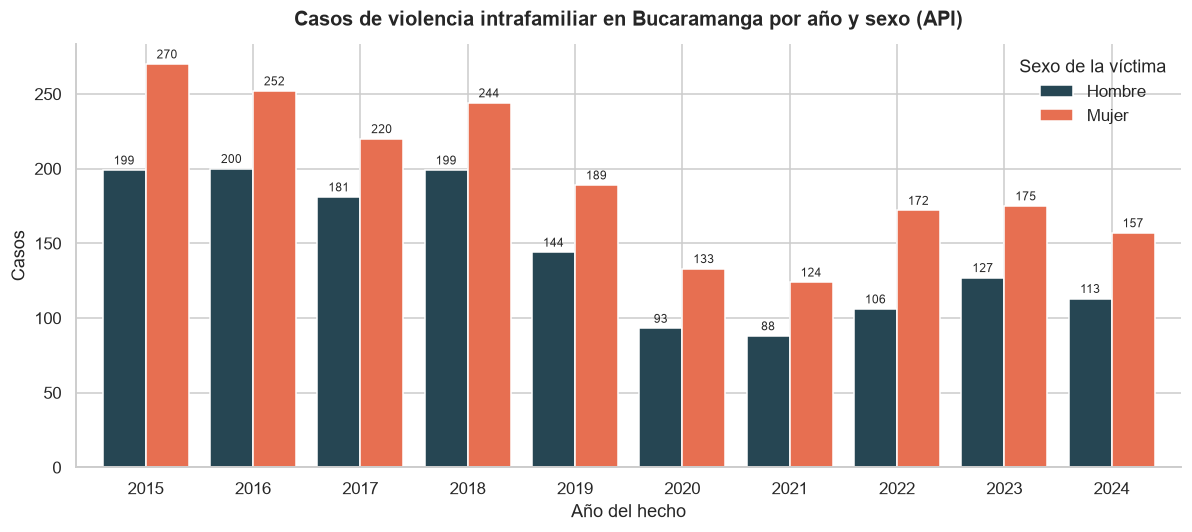

Porcentaje de víctimas mujeres por año: {'2015': 57.6, '2016': 55.8, '2017': 54.9, '2018': 55.1, '2019': 56.8, '2020': 58.8, '2021': 58.5, '2022': 61.9, '2023': 57.9, '2024': 58.1}


In [73]:
# Casos por año y sexo
tabla = pd.crosstab(api_bga[C_ANIO], api_bga[C_SEXO])
ax = tabla.plot(kind="bar", figsize=(11, 5), color=["#264653", "#E76F51"][: tabla.shape[1]], width=0.8)
for cont in ax.containers:
    ax.bar_label(cont, fontsize=8, padding=2)
ax.set_title("Casos de violencia intrafamiliar en Bucaramanga por año y sexo (API)")
ax.set_xlabel("Año del hecho")
ax.set_ylabel("Casos")
ax.legend(title="Sexo de la víctima")
plt.xticks(rotation=0)
plt.tight_layout()
guardar("08_api_casos_anio_sexo.png")
plt.show()

pct_mujer = (tabla.get("Mujer", 0) / tabla.sum(axis=1) * 100).round(1)
print("Porcentaje de víctimas mujeres por año:", pct_mujer.to_dict())

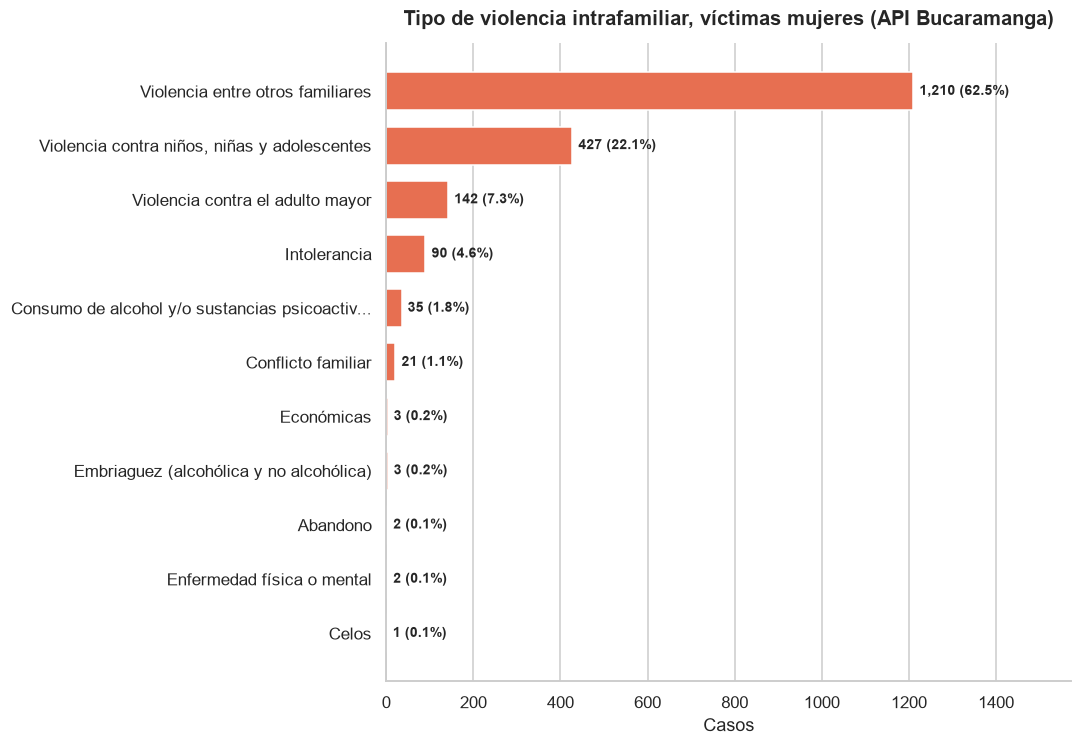

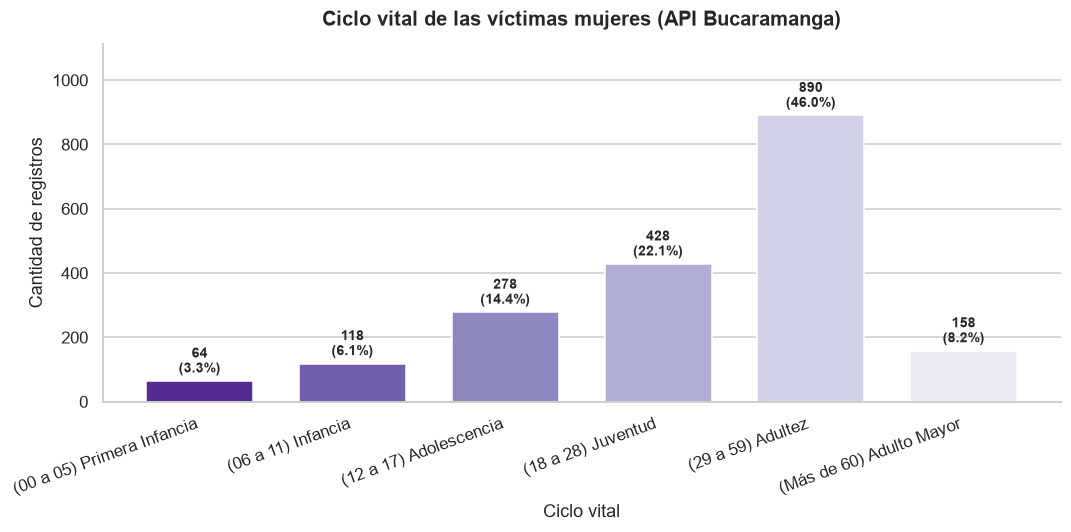

In [74]:
# Tipo de violencia y ciclo vital (víctimas mujeres)
barras_horizontales(mujeres_api[C_TIPO].value_counts(), "Tipo de violencia intrafamiliar, víctimas mujeres (API Bucaramanga)",
                    "Casos", "09_api_tipo_violencia_mujeres.png", color="#E76F51")
barras_verticales(mujeres_api[C_CICLO].value_counts().sort_index(), "Ciclo vital de las víctimas mujeres (API Bucaramanga)",
                  "Ciclo vital", "10_api_ciclo_vital_mujeres.png", color=sns.color_palette("Purples_r", mujeres_api[C_CICLO].nunique()), rotar=20)

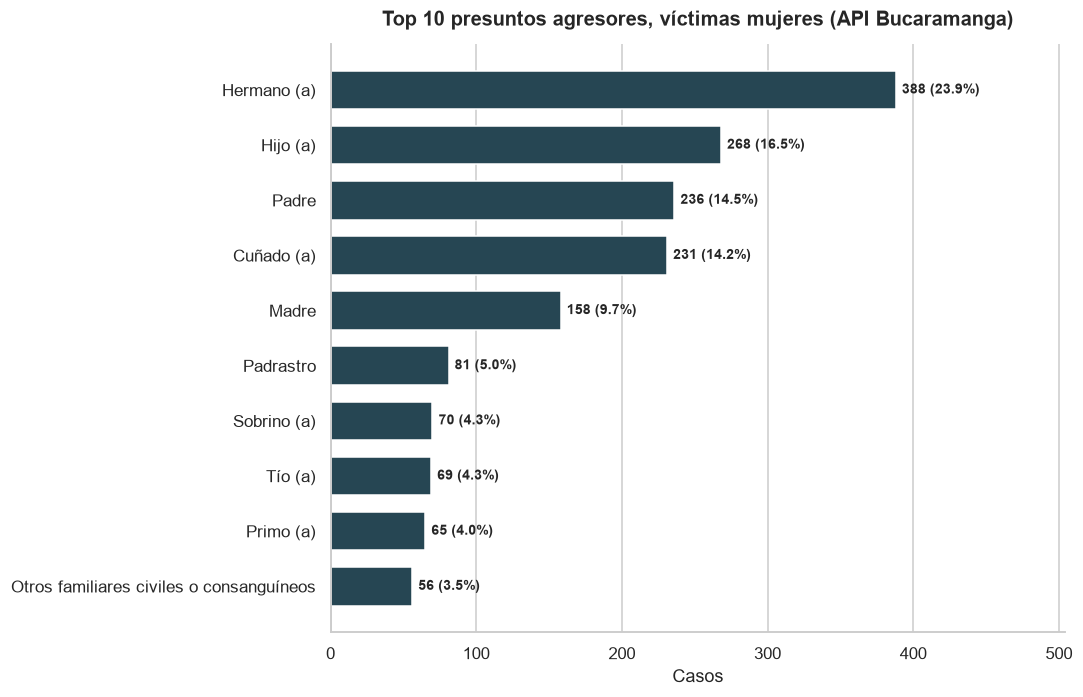

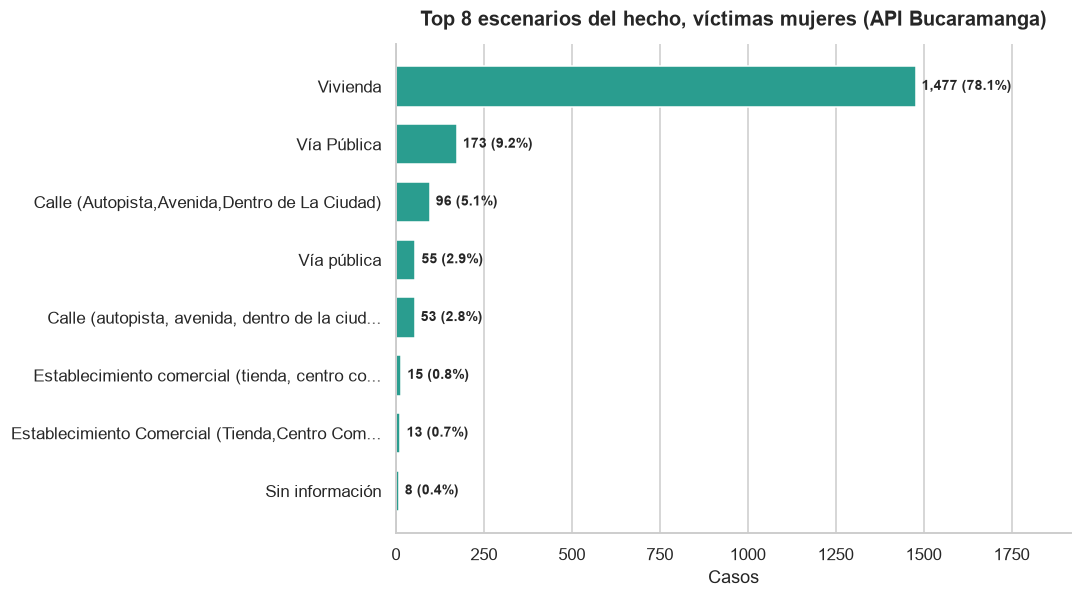

In [75]:
# Presunto agresor (top 10) y escenario (top 8), víctimas mujeres
barras_horizontales(mujeres_api[C_AGRESOR].value_counts().head(10), "Top 10 presuntos agresores, víctimas mujeres (API Bucaramanga)",
                    "Casos", "11_api_agresor_mujeres.png", color="#264653")
barras_horizontales(mujeres_api[C_ESC].value_counts().head(8), "Top 8 escenarios del hecho, víctimas mujeres (API Bucaramanga)",
                    "Casos", "12_api_escenario_mujeres.png", color="#2A9D8F")

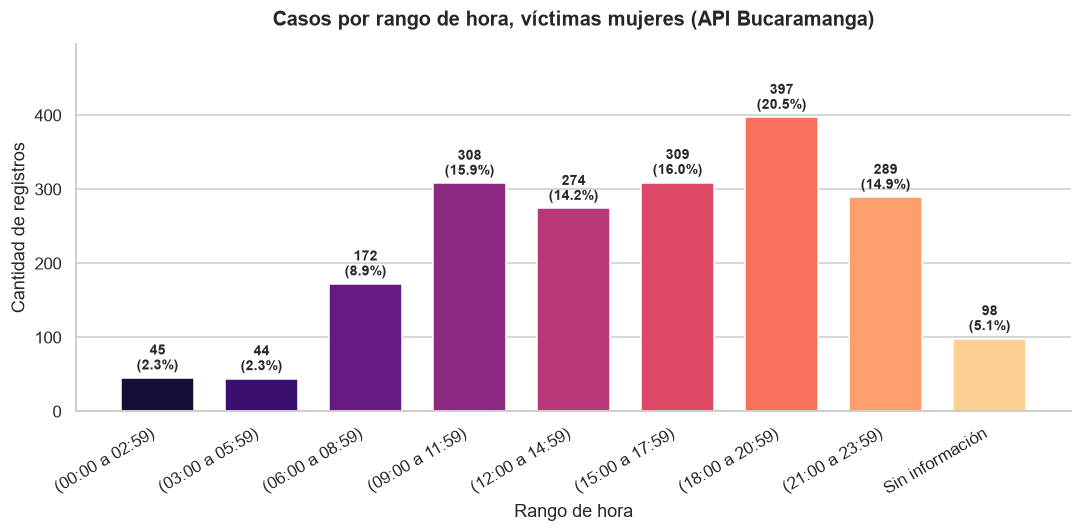

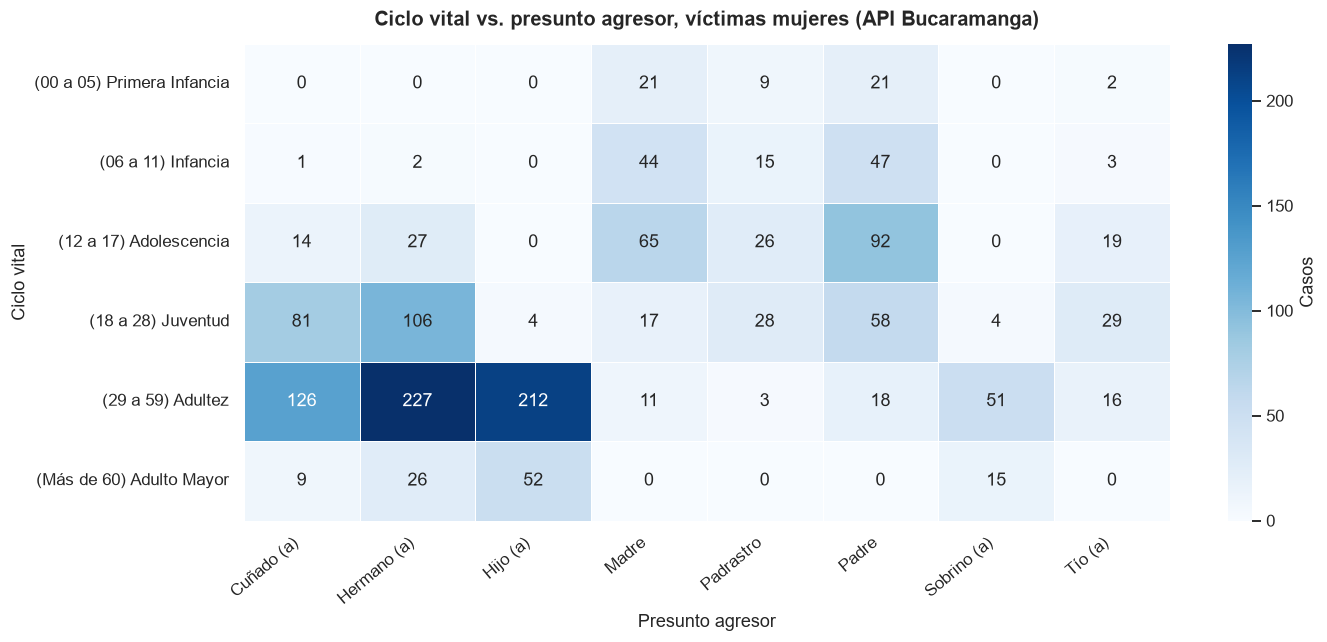

In [76]:
# Rango de hora del hecho y mapa de calor ciclo vital vs. agresor (víctimas mujeres)
barras_verticales(mujeres_api[C_HORA].value_counts().sort_index(), "Casos por rango de hora, víctimas mujeres (API Bucaramanga)",
                  "Rango de hora", "13_api_rango_hora_mujeres.png", color=sns.color_palette("magma", mujeres_api[C_HORA].nunique()), rotar=30)

m = mujeres_api[(mujeres_api[C_CICLO] != "Sin información") & (mujeres_api[C_AGRESOR] != "Sin información")]
top_agr = m[C_AGRESOR].value_counts().head(8).index
pivot = pd.crosstab(m[C_CICLO], m.loc[m[C_AGRESOR].isin(top_agr), C_AGRESOR])
pivot.columns = [corto(c, 25) for c in pivot.columns]
plt.figure(figsize=(13, 6))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Blues", linewidths=0.5, cbar_kws={"label": "Casos"})
plt.title("Ciclo vital vs. presunto agresor, víctimas mujeres (API Bucaramanga)")
plt.xlabel("Presunto agresor")
plt.ylabel("Ciclo vital")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
guardar("14_api_ciclo_vs_agresor.png")
plt.show()

**Alcance de la fuente: violencia entre familiares, sin violencia de pareja.** En los casos de Bucaramanga no aparece ningún agresor que sea pareja o expareja. La columna `contexto_del_hecho` lo explica: el conjunto solo incluye lesiones por violencia "entre otros familiares", "contra niños, niñas y adolescentes" y "contra el adulto mayor". Medicina Legal publica la **violencia de pareja en un conjunto aparte**. Por eso esta fuente **no repite** la información de SIVIGILA, sino que la complementa con la violencia que ejercen otros familiares (hermanos, padres, hijos, cuñados). Al comparar las dos fuentes por tipo de agresor, la comparación se hace solo entre las categorías familiares

### 3.8 Bucaramanga comparada con el país

Con la muestra nacional de 50.000 registros comparamos el perfil de Bucaramanga con el del país **en los mismos años** que cubre la muestra. Comparamos porcentajes y no cantidades, porque el tamaño de las dos tablas es muy distinto

Años de la comparación: ['2022', '2023', '2024']
Casos de Bucaramanga en esos años: 850 | casos del país en la muestra: 50,000


,Bucaramanga,Colombia (muestra)
% víctimas mujeres,59.3,58.4
% casos con agresor pareja o expareja,0.0,0.0


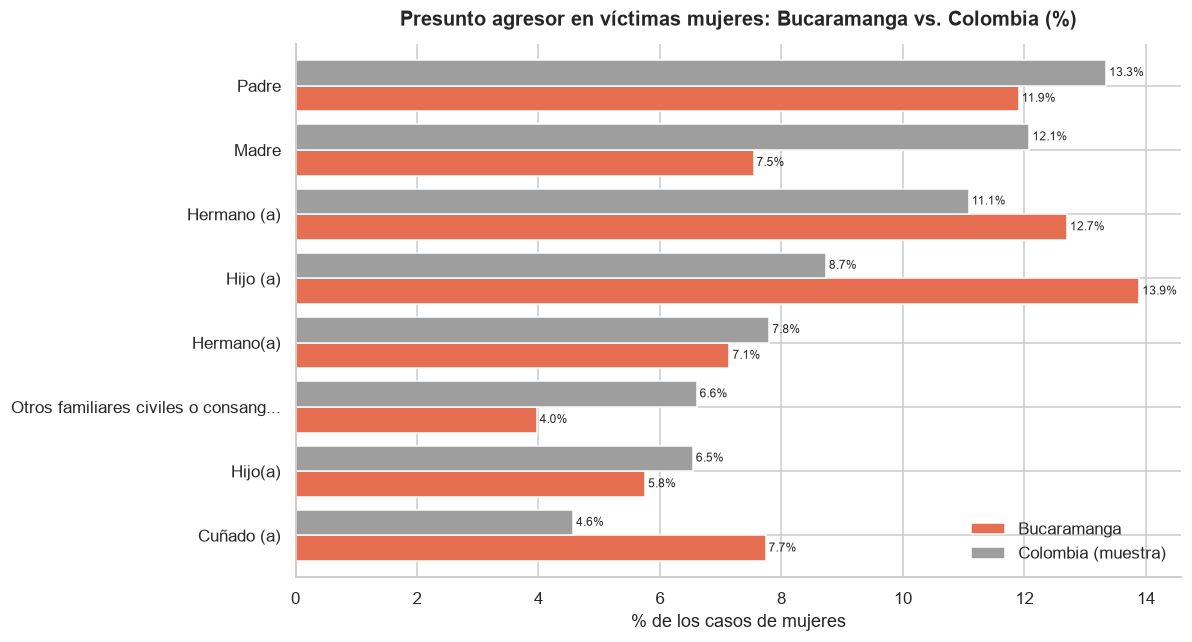

In [77]:
anios_nal = sorted(api_nal[C_ANIO].dropna().unique()) if len(api_nal) else []
bga_comp = api_bga[api_bga[C_ANIO].isin(anios_nal)]
print(f"Años de la comparación: {anios_nal}")
print(f"Casos de Bucaramanga en esos años: {len(bga_comp):,} | casos del país en la muestra: {len(api_nal):,}")


def pct(df_, col, valor):
    return round((df_[col] == valor).mean() * 100, 1) if len(df_) else None


comparacion = pd.DataFrame({
    "Bucaramanga": [pct(bga_comp, C_SEXO, "Mujer"),
                    round(bga_comp[C_AGRESOR].str.contains("pareja", case=False, na=False).mean() * 100, 1)],
    "Colombia (muestra)": [pct(api_nal, C_SEXO, "Mujer"),
                           round(api_nal[C_AGRESOR].str.contains("pareja", case=False, na=False).mean() * 100, 1) if len(api_nal) else None],
}, index=["% víctimas mujeres", "% casos con agresor pareja o expareja"])
display(comparacion)

if len(api_nal) and len(bga_comp):
    mb = bga_comp[bga_comp[C_SEXO] == "Mujer"]
    mn = api_nal[api_nal[C_SEXO] == "Mujer"]
    top_n = mn[C_AGRESOR].value_counts().head(8).index
    comp_agr = pd.DataFrame({
        "Bucaramanga": mb[C_AGRESOR].value_counts(normalize=True).reindex(top_n).fillna(0) * 100,
        "Colombia (muestra)": mn[C_AGRESOR].value_counts(normalize=True).reindex(top_n).fillna(0) * 100,
    })
    comp_agr.index = [corto(i, 35) for i in comp_agr.index]
    ax = comp_agr.iloc[::-1].plot(kind="barh", figsize=(11, 6), color=["#E76F51", "#9E9E9E"], width=0.8)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.1f%%", fontsize=8, padding=2)
    ax.set_title("Presunto agresor en víctimas mujeres: Bucaramanga vs. Colombia (%)")
    ax.set_xlabel("% de los casos de mujeres")
    ax.legend(loc="lower right")
    plt.tight_layout()
    guardar("15_api_bucaramanga_vs_colombia.png")
    plt.show()

### 3.9 Observaciones de la API

- La consulta filtrada trae todos los casos de Bucaramanga (2015-2024), lo que cambia completamente la calidad del análisis frente a la versión anterior, que tomaba una muestra nacional concentrada en 2015
- Todo llega como texto y la falta de dato casi siempre viene escrita ("Sin información", "No aplica"), no como nulo
- Hay columnas casi vacías (más del 90 % sin dato) que no aportan y no pasan al modelo
- La hora viene en rangos de 3 horas, y `etl/turno.py` ya la convierte al mismo turno que usa SIVIGILA
- La fuente incluye víctimas hombres y mujeres. En la capa cruda se guardan todos y el filtro de mujeres se aplica en la transformación, así queda documentado cuántos casos se excluyen
- Los días de incapacidad se publican en rangos y no como número; se tratan como categoría ordenada y los casos graves (más de 30 días) se conservan
- El conjunto no incluye violencia de pareja (Medicina Legal la publica aparte): complementa a SIVIGILA con la violencia de otros familiares
- Una misma categoría aparece escrita de varias formas (mayúsculas, tildes, espacios antes del paréntesis), así que se normaliza antes de homologar
- Los nombres de las categorías (agresor, ciclo vital, escenario) son distintos a los de SIVIGILA, así que para comparar las dos fuentes hace falta una **tabla de homologación** (Parte 6)

## Parte 4. Fuente 3: CSV de vivienda (ECV 2024)

Qué es: la tabla de vivienda de la Encuesta Nacional de Calidad de Vida 2024 del DANE. Cada fila es una vivienda encuestada

Para qué la usamos: para dar contexto socioeconómico de Bucaramanga (estrato, tipo de vivienda y zona). Esta fuente no contiene personas ni casos de violencia, así que cualquier relación que encontremos con la violencia es descriptiva y no demuestra que una cosa cause la otra. Además, la encuesta no trae la comuna, solo el municipio y la zona (cabecera o centro poblado)

### 4.1 Perfil del archivo completo (nacional)

In [78]:
def perfil_texto(df):
    return pd.DataFrame({
        "nulos": df.isna().sum(),
        "pct_nulos": (df.isna().mean() * 100).round(2),
        "distintos": df.nunique(),
        "largo_min": df.apply(lambda s: s.str.len().min()),
        "largo_max": df.apply(lambda s: s.str.len().max()),
        "ejemplo": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
    })


print(f"Filas: {len(viv):,} | Columnas leídas: {viv.shape[1]} de {N_COLS_ARCHIVO}")
print(f"Filas duplicadas (en las 6 columnas): {int(viv.duplicated().sum()):,}")
display(perfil_texto(viv))

Filas: 85,106 | Columnas leídas: 6 de 43
Filas duplicadas (en las 6 columnas): 80,683


,nulos,pct_nulos,distintos,largo_min,largo_max,ejemplo
P1_DEPARTAMENTO,0,0.00,33,2.0,2.0,08
P1_MUNICIPIO,0,0.00,405,3.0,3.0,001
CLASE,0,0.00,2,1.0,1.0,1
P1070,0,0.00,5,1.0,1.0,2
P8520S1,0,0.00,2,1.0,1.0,1
P8520S1A1,3166,3.72,9,1.0,1.0,2


Las 6 columnas son códigos y todos tienen el largo esperado (2 dígitos el departamento, 3 el municipio, 1 los demás). Solo el estrato tiene nulos, y en la parte 4.4 se ve que esos nulos tienen una explicación

Las filas "duplicadas" son muchísimas, pero no son un error. Como solo leemos 6 columnas de códigos, es normal que miles de viviendas compartan los mismos valores (por ejemplo, muchas casas de estrato 2 en cabecera con energía). Para saber si una fila repetida es la misma vivienda haría falta la columna `DIRECTORIO`, que identifica a cada vivienda y no está en nuestro alcance. Por eso **no se eliminan duplicados en esta fuente**

### 4.2 Alcance geográfico: Bucaramanga

In [79]:
dep = viv["P1_DEPARTAMENTO"].str.zfill(2)
mun = viv["P1_MUNICIPIO"]
print("Largo de P1_MUNICIPIO:", mun.str.len().value_counts(dropna=False).to_dict())

divipola = dep + mun.str.zfill(3)      # código de 5 dígitos, solo para filtrar en el EDA
alcance = pd.DataFrame(
    {"filas": [len(viv), int((dep == "68").sum()), int((divipola == "68001").sum())]},
    index=["Archivo completo (nacional)", "Santander (P1_DEPARTAMENTO = 68)", "Bucaramanga (68001)"],
)
alcance["pct_del_archivo"] = (alcance["filas"] / len(viv) * 100).round(2)
display(alcance)

vb = viv[divipola == "68001"].copy()
print(f"Viviendas de Bucaramanga: {len(vb):,}")

Largo de P1_MUNICIPIO: {3: 85106}


,filas,pct_del_archivo
Archivo completo (nacional),85106,100.00
Santander (P1_DEPARTAMENTO = 68),3034,3.56
Bucaramanga (68001),432,0.51


Viviendas de Bucaramanga: 432


### 4.3 Frecuencias de las variables en Bucaramanga

Cada tabla muestra el código, su significado según el diccionario del DANE y cuántas viviendas lo tienen. Si apareciera un código que no está en el diccionario, saldría como CÓDIGO NO DOCUMENTADO

In [80]:
def a_codigo(s):
    # Texto a entero (nulo si no es numérico). Solo para perfilar
    return pd.to_numeric(s, errors="coerce").round().astype("Int64")


ETIQUETAS = {
    "CLASE": {1: "Cabecera", 2: "Centro poblado / corregimiento", 3: "Rural disperso"},
    "P1070": {1: "Casa", 2: "Apartamento", 3: "Cuarto(s)", 4: "Vivienda tradicional indígena", 5: "Otro"},
    "P8520S1": {1: "Sí cuenta", 2: "No cuenta"},
    "P8520S1A1": {0: "Sin estrato / pirata", 1: "Estrato 1", 2: "Estrato 2", 3: "Estrato 3",
                  4: "Estrato 4", 5: "Estrato 5", 6: "Estrato 6", 8: "Planta eléctrica",
                  9: "No sabe el estrato / sin recibo"},
}


def frecuencias(df, col):
    s = a_codigo(df[col])
    t = s.value_counts(dropna=False).sort_index().rename("viviendas").to_frame()
    t["pct"] = (t["viviendas"] / len(s) * 100).round(2)
    t.insert(0, "significado", ["VACÍO O NO NUMÉRICO" if pd.isna(i) else ETIQUETAS[col].get(int(i), "CÓDIGO NO DOCUMENTADO") for i in t.index])
    t.index.name = col
    return t


for col in ["CLASE", "P1070", "P8520S1", "P8520S1A1"]:
    no_numerico = vb[col].notna() & a_codigo(vb[col]).isna()
    print(f"\n--- {col}  (Bucaramanga, n = {len(vb):,}) ---")
    if no_numerico.any():
        print(f"ATENCIÓN: {int(no_numerico.sum())} valores no numéricos, ej.: {list(vb.loc[no_numerico, col].unique()[:3])}")
    display(frecuencias(vb, col))


--- CLASE  (Bucaramanga, n = 432) ---


,significado,viviendas,pct
CLASE,,,
1,Cabecera,366,84.72
2,Centro poblado / corregimiento,66,15.28



--- P1070  (Bucaramanga, n = 432) ---


,significado,viviendas,pct
P1070,,,
1,Casa,168,38.89
2,Apartamento,256,59.26
3,Cuarto(s),8,1.85



--- P8520S1  (Bucaramanga, n = 432) ---


,significado,viviendas,pct
P8520S1,,,
1,Sí cuenta,431,99.77
2,No cuenta,1,0.23



--- P8520S1A1  (Bucaramanga, n = 432) ---


,significado,viviendas,pct
P8520S1A1,,,
0,Sin estrato / pirata,3,0.69
1,Estrato 1,124,28.7
2,Estrato 2,71,16.44
3,Estrato 3,118,27.31
4,Estrato 4,81,18.75
5,Estrato 5,17,3.94
6,Estrato 6,16,3.7
8,Planta eléctrica,1,0.23
<NA>,VACÍO O NO NUMÉRICO,1,0.23


### 4.4 Calidad del estrato y valores atípicos

En esta fuente no hay variables continuas (todas son códigos), así que los "valores atípicos" son los **códigos que no son un estrato**. Los estratos válidos son del 1 al 6; los códigos 0 (sin estrato o conexión pirata), 8 (planta eléctrica) y 9 (no sabe), y el campo vacío, no son estratos y no se pueden usar para comparar niveles socioeconómicos. También revisamos si el estrato vacío se explica porque la vivienda no tiene energía

In [81]:
est = a_codigo(vb["P8520S1A1"])
ener = a_codigo(vb["P8520S1"])
en_alcance = est.between(1, 6).fillna(False).astype(bool)


def motivo(v):
    if pd.isna(v):
        return "Vacío (sin energía eléctrica o sin dato)"
    return {0: "0 = Sin estrato / pirata", 8: "8 = Planta eléctrica", 9: "9 = No sabe / sin recibo"}.get(int(v), f"{int(v)} = código no documentado")


n = len(vb)
print(f"Viviendas de Bucaramanga: {n:,}")
print(f"  Con estrato 1 a 6: {int(en_alcance.sum()):,} ({en_alcance.mean() * 100:.1f}%)")
print(f"  Con otro código o vacío: {int((~en_alcance).sum()):,} ({(~en_alcance).mean() * 100:.1f}%)")
print("\nMotivo de las que no tienen estrato 1 a 6:")
print(est[~en_alcance].map(motivo).value_counts().to_string())

print("\nCruce P8520S1 (filas) x P8520S1A1 (columnas)   [-1 = vacío]")
display(pd.crosstab(ener.fillna(-1), est.fillna(-1), margins=True))

regla = (est.isna() == (ener == 2).fillna(False)).mean() * 100
print(f"Regla 'estrato vacío <=> sin energía (P8520S1 = 2)': se cumple en {regla:.1f}% de las viviendas")
valores_energia = sorted(int(v) for v in ener[en_alcance].dropna().unique())
print(f"Valores de P8520S1 entre las viviendas con estrato 1 a 6: {valores_energia}")

Viviendas de Bucaramanga: 432
  Con estrato 1 a 6: 427 (98.8%)
  Con otro código o vacío: 5 (1.2%)

Motivo de las que no tienen estrato 1 a 6:
P8520S1A1
0 = Sin estrato / pirata                    3
Vacío (sin energía eléctrica o sin dato)    1
8 = Planta eléctrica                        1

Cruce P8520S1 (filas) x P8520S1A1 (columnas)   [-1 = vacío]


P8520S1A1,-1,0,1,2,3,4,5,6,8,All
P8520S1,,,,,,,,,,
1,0,3,124,71,118,81,17,16,1,431
2,1,0,0,0,0,0,0,0,0,1
All,1,3,124,71,118,81,17,16,1,432


Regla 'estrato vacío <=> sin energía (P8520S1 = 2)': se cumple en 100.0% de las viviendas
Valores de P8520S1 entre las viviendas con estrato 1 a 6: [1]


El estrato vacío no es un error de la encuesta: aparece exactamente en las viviendas que no tienen energía eléctrica, porque el estrato se pregunta a partir del recibo de la luz. Además, entre las viviendas con estrato 1 a 6 la variable de energía siempre vale 1 (sí cuenta), es decir que **no aporta variación** una vez se filtra por estrato válido. La conservamos en la tabla de hechos porque sirve como control de calidad (una regla de Great Expectations puede revisar que todas las viviendas con estrato tengan energía)

Las viviendas con códigos 0, 8, 9 o vacío son muy pocas y se excluyen de la carga, tal como ya lo establece el CHECK de `dim_estrato` (`id_estrato BETWEEN 1 AND 6`)

### 4.5 Variables clave, estadísticas básicas y gráficas

Las variables clave de esta fuente son el estrato, el tipo de vivienda y la zona. Las gráficas usan solo las viviendas de Bucaramanga

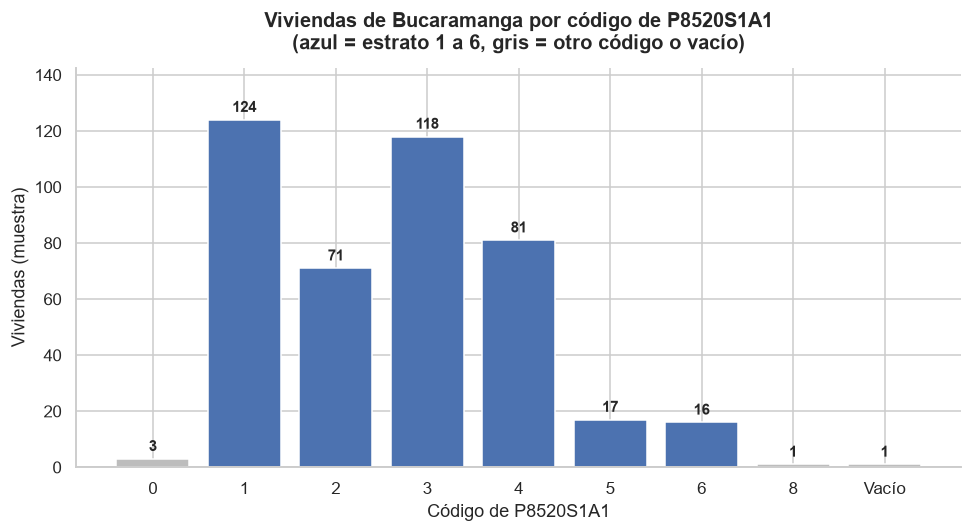

Estrato (solo 1 a 6): mediana = 3, moda = 1
Viviendas en estratos 1 y 2 (bajo-bajo y bajo): 45.7%
Viviendas en estratos 5 y 6 (medio-alto y alto): 7.7%


In [82]:
conteo = est.value_counts(dropna=False).sort_index()
etiquetas = ["Vacío" if pd.isna(c) else str(int(c)) for c in conteo.index]
colores_est = ["#4C72B0" if (not pd.isna(c) and 1 <= c <= 6) else "#BDBDBD" for c in conteo.index]
fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.bar(etiquetas, conteo.values, color=colores_est)
ax.bar_label(barras, labels=[f"{v:,}" for v in conteo.values], padding=3, fontsize=10, fontweight="bold")
ax.set_title("Viviendas de Bucaramanga por código de P8520S1A1\n(azul = estrato 1 a 6, gris = otro código o vacío)")
ax.set_xlabel("Código de P8520S1A1")
ax.set_ylabel("Viviendas (muestra)")
ax.set_ylim(0, max(conteo.max(), 1) * 1.15)
plt.tight_layout()
guardar("16_viv_distribucion_estrato.png")
plt.show()

est_valido = est[en_alcance].astype(int)
print(f"Estrato (solo 1 a 6): mediana = {est_valido.median():.0f}, moda = {est_valido.mode().iloc[0]}")
print(f"Viviendas en estratos 1 y 2 (bajo-bajo y bajo): {est_valido.isin([1, 2]).mean() * 100:.1f}%")
print(f"Viviendas en estratos 5 y 6 (medio-alto y alto): {est_valido.isin([5, 6]).mean() * 100:.1f}%")

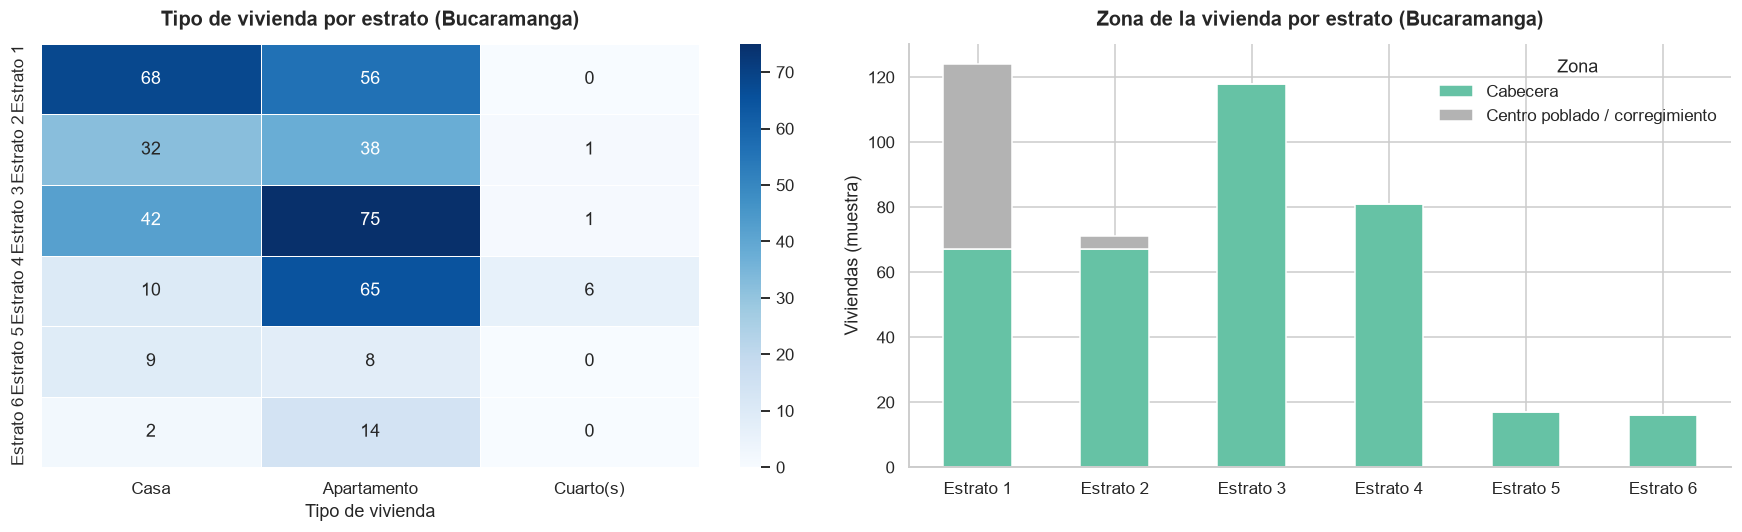

In [83]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ct_tipo = pd.crosstab(est[en_alcance], a_codigo(vb["P1070"])[en_alcance])
ct_tipo.index = [f"Estrato {int(i)}" for i in ct_tipo.index]
ct_tipo.columns = [ETIQUETAS["P1070"].get(int(c), f"Código {int(c)}") for c in ct_tipo.columns]
sns.heatmap(ct_tipo, annot=True, fmt="d", cmap="Blues", linewidths=0.5, ax=axes[0])
axes[0].set_title("Tipo de vivienda por estrato (Bucaramanga)")
axes[0].set_xlabel("Tipo de vivienda")
axes[0].set_ylabel("")

ct_clase = pd.crosstab(est[en_alcance], a_codigo(vb["CLASE"])[en_alcance])
ct_clase.index = [f"Estrato {int(i)}" for i in ct_clase.index]
ct_clase.columns = [ETIQUETAS["CLASE"].get(int(c), f"Código {int(c)}") for c in ct_clase.columns]
ct_clase.plot(kind="bar", stacked=True, colormap="Set2", ax=axes[1])
axes[1].set_title("Zona de la vivienda por estrato (Bucaramanga)")
axes[1].set_xlabel("")
axes[1].set_ylabel("Viviendas (muestra)")
axes[1].legend(title="Zona")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
guardar("17_viv_tipo_y_zona_por_estrato.png")
plt.show()

### 4.6 Observaciones de la vivienda

- El archivo es de buena calidad: sin códigos fuera del diccionario y con todos los largos esperados
- Bucaramanga es una parte pequeña del archivo nacional, porque es una muestra de encuesta y no un censo. Las cifras sirven para describir proporciones (qué parte de las viviendas es de cada estrato), no para contar viviendas reales
- El estrato vacío se explica por la falta de energía, y los códigos 0, 8 y 9 no son estratos. Solo se cargan los estratos 1 a 6
- La zona (`CLASE`) es la única variable que se puede relacionar con las fuentes de violencia, porque SIVIGILA también registra si el caso fue en cabecera, centro poblado o rural. La encuesta no trae comuna
- Los "duplicados" son normales en una encuesta leída con pocas columnas y no se eliminan

## Parte 5. Fuente 4: dataset de la primera entrega (SIVIGILA Bucaramanga)

En la primera entrega esta fuente se analizó a fondo. Aquí revisamos su calidad con las mismas preguntas que las demás fuentes y, sobre todo, lo que necesitamos para integrarla con las fuentes nuevas: si la comuna se puede unir con el OSEC, cómo vienen la fecha y la hora, y qué tan completas están las variables que vamos a comparar con la API

Para no depender de que el archivo tenga exactamente los mismos nombres de columna, cada revisión primero verifica que la columna exista

In [84]:
def col(nombre):
    # Devuelve el nombre de la columna si existe en el CSV (sin importar mayúsculas), o None
    for c in siv.columns:
        if c.strip().lower() == nombre.strip().lower():
            return c
    return None


S_ORDEN, S_ANIO, S_SEMANA, S_SEXO = col("Orden"), col("año"), col("semana"), col("sexo_")
S_MUN, S_DEP, S_AREA, S_COMUNA, S_BARRIO = col("Municipio"), col("Departamento"), col("area_"), col("Comuna"), col("Barrio")
S_CICLO, S_NAT, S_DEFNAT = col("Ciclo de vida"), col("naturaleza"), col("def_naturaleza")
S_EDAD_AGRE, S_SEXO_AGRE, S_PAREN = col("edad_agre"), col("sexo_agre"), col("parentezco_vict")
S_FECHA, S_HORA, S_CONFIN, S_ESC = col("fec_hecho"), col("hora_hecho"), col("con_fin_"), col("escenario")

print("Columnas que no se encontraron:", [n for n, c in {
    "Orden": S_ORDEN, "año": S_ANIO, "sexo_": S_SEXO, "Municipio": S_MUN, "area_": S_AREA, "Comuna": S_COMUNA,
    "naturaleza": S_NAT, "edad_agre": S_EDAD_AGRE, "parentezco_vict": S_PAREN, "fec_hecho": S_FECHA,
    "hora_hecho": S_HORA, "con_fin_": S_CONFIN}.items() if c is None] or "ninguna")

Columnas que no se encontraron: ninguna


### 5.1 Estructura y tipos de datos

In [85]:
display(siv.head(3))
display(perfil_columnas(siv))
print("Columnas que llegan como texto pero parecen números:", parecen_numero(siv))

,Orden,Departamento,Municipio,semana,año,Grupo edad,Ciclo de vida,sexo_,area_,Barrio,Comuna,Tipo de Seguridad Social,pac_hos_,con_fin_,version,naturaleza,def_naturaleza,actividad,nom_actividad,edad_agre,sexo_agre,parentezco_vict,sust_vict,fec_hecho,hora_hecho,escenario,zona_conf,nom_eve,nom_upgd,ndep_resi,nmun_resi,MES
0,1,SANTANDER,BUCARAMANGA,23,2015,12 a 17,Adolescencia,Masculino,CABECERA MUNICIPAL,Transicion I-V,02. NORORIENTAL,No asegurado,2,1,SIVIGILA - 2015 - 15.1.3,3,Negligencia y abandono,26,Otro,33,Masculino,Padre,2,2015-06-12,06:30:00 a. m.,1,2,VIGILANCIA EN SALUD PÚBLICA DE LAS VIOLENCIAS DE GÉNERO,SERVICLINICOS DROMEDICA SA,SANTANDER,BUCARAMANGA,06. junio
1,2,SANTANDER,BUCARAMANGA,5,2015,12 a 17,Adolescencia,Masculino,CABECERA MUNICIPAL,Betania,01. NORTE,Subsidiado,2,1,SIVIGILA - 2015 - 15.1.1,1,Violencia fisica,24,Estudiante,27,Masculino,Otros,2,2015-02-04,10:00:00 a. m.,1,2,VIGILANCIA EN SALUD PÚBLICA DE LAS VIOLENCIAS DE GÉNERO,HOSPITAL LOCAL DEL NORTE,SANTANDER,BUCARAMANGA,02. febrero
2,3,SANTANDER,BUCARAMANGA,29,2015,12 a 17,Adolescencia,Femenino,CABECERA MUNICIPAL,GIRON,GIRON,Subsidiado,1,1,SIVIGILA - 2015 - 15.1.3,3,Negligencia y abandono,26,Otro,13,Femenino,Madre,2,2015-07-21,08:00:00 a. m.,2,2,VIGILANCIA EN SALUD PÚBLICA DE LAS VIOLENCIAS DE GÉNERO,HOSPITAL UNIVERSITARIO DE SANTANDER,SANTANDER,BUCARAMANGA,07. julio


,tipo,nulos,pct_nulos,distintos,ejemplo
Orden,str,0,0.00,17104,1
Departamento,str,0,0.00,15,SANTANDER
Municipio,str,0,0.00,38,BUCARAMANGA
semana,str,0,0.00,53,23
año,str,0,0.00,11,2015
Grupo edad,str,0,0.00,6,12 a 17
Ciclo de vida,str,0,0.00,6,Adolescencia
sexo_,str,0,0.00,2,Masculino
area_,str,0,0.00,3,CABECERA MUNICIPAL
Barrio,str,0,0.00,480,Transicion I-V


Columnas que llegan como texto pero parecen números: ['Orden', 'semana', 'año', 'pac_hos_', 'con_fin_', 'naturaleza', 'actividad', 'edad_agre', 'sust_vict', 'escenario', 'zona_conf']


Igual que en las otras fuentes, el CSV se lee todo como texto (así lo hace `etl/ingesta.py`, para que la tabla cruda guarde los valores originales). Las columnas que parecen números son los códigos y las cifras del caso: año, semana, edad del agresor, naturaleza, entre otras. Su conversión ya está resuelta en `etl/transformacion.py` desde la primera entrega

### 5.2 Valores faltantes

Celdas vacías en toda la tabla: 2.2%
Columnas con nulos reales: 3 de 32


,nulos,pct_nulos
hora_hecho,11442,66.90
nom_upgd,598,3.50
nmun_resi,1,0.01


Columnas con textos tipo 'sin información':


,valores_sin_dato,pct
columna,,
Comuna,1538,8.99
Barrio,1472,8.61
def_naturaleza,317,1.85


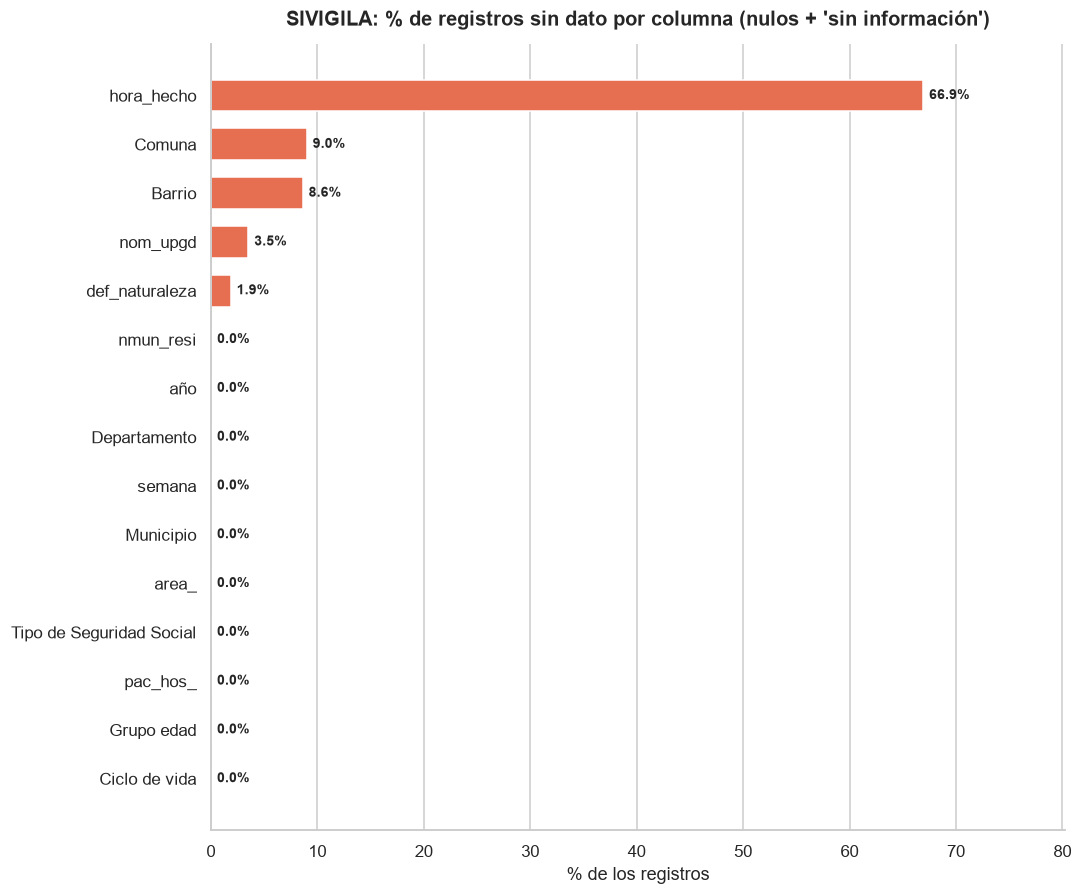

In [86]:
nulos_siv = perfil_columnas(siv)[["nulos", "pct_nulos"]].sort_values("pct_nulos", ascending=False)
print(f"Celdas vacías en toda la tabla: {pct_vacio(siv)}%")
print(f"Columnas con nulos reales: {int((nulos_siv['nulos'] > 0).sum())} de {siv.shape[1]}")
display(nulos_siv[nulos_siv["nulos"] > 0].head(15))

sin_dato_siv = contar_sin_dato(siv, excluir=(S_ORDEN,))
print("Columnas con textos tipo 'sin información':")
display(sin_dato_siv[sin_dato_siv["valores_sin_dato"] > 0].head(10))

faltante_total = (nulos_siv["pct_nulos"] + sin_dato_siv["pct"].reindex(nulos_siv.index).fillna(0)).sort_values(ascending=False).head(15)
if faltante_total.max() > 0:
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(faltante_total) + 2))
    y = np.arange(len(faltante_total))[::-1]
    b = ax.barh(y, faltante_total.values, color=FUENTES["sivigila"]["color"], height=0.65)
    ax.set_yticks(y, labels=faltante_total.index)
    ax.bar_label(b, labels=[f"{p:.1f}%" for p in faltante_total.values], padding=4, fontsize=9, fontweight="bold")
    ax.set_xlim(0, max(faltante_total.max() * 1.2, 5))
    ax.set_title("SIVIGILA: % de registros sin dato por columna (nulos + 'sin información')")
    ax.set_xlabel("% de los registros")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    guardar("18_siv_faltantes.png")
    plt.show()

### 5.3 Duplicados

`Orden` es el consecutivo del registro en el archivo, así que lo excluimos al buscar filas repetidas (igual que el `id` de la API)

In [87]:
cols_sin_orden = [c for c in siv.columns if c != S_ORDEN]
dup_siv = int(siv.duplicated(subset=cols_sin_orden).sum())
print(f"Filas idénticas en todas las columnas: {int(siv.duplicated().sum())}")
print(f"Filas repetidas sin contar '{S_ORDEN}': {dup_siv:,} ({dup_siv / len(siv) * 100:.2f}%)")
if S_ORDEN:
    print(f"'{S_ORDEN}' es único: {siv[S_ORDEN].is_unique}")

Filas idénticas en todas las columnas: 0
Filas repetidas sin contar 'Orden': 36 (0.21%)
'Orden' es único: True


### 5.4 Formatos de fecha y hora

En la primera entrega encontramos que la hora viene en formato de 12 horas con "a. m." / "p. m." y que el valor "12:00:00 a. m." aparece muchísimo más que cualquier otra hora, lo que suele ser un marcador de "hora desconocida". Aquí lo revisamos de nuevo con la misma función que usa el pipeline

In [88]:
if S_HORA:
    print("Formatos de la hora:")
    display(diagnosticar_formatos(siv[S_HORA]))
    top_horas = siv[S_HORA].value_counts().head(5)
    print("Las 5 horas más frecuentes:")
    print(top_horas.to_string())
    if len(top_horas) > 1:
        print(f"\nLa hora más frecuente aparece {top_horas.iloc[0] / top_horas.iloc[1]:.1f} veces más que la segunda")

if S_FECHA:
    f = siv[S_FECHA].astype("string").str.strip()
    formato = np.select(
        [f.isna(), f.str.match(r"^\d{4}[-/]\d{1,2}[-/]\d{1,2}", na=False), f.str.match(r"^\d{1,2}[-/]\d{1,2}[-/]\d{4}", na=False)],
        ["vacío", "año primero (aaaa-mm-dd)", "día primero (dd/mm/aaaa)"], default="otro formato")
    print("\nFormatos de la fecha del hecho:")
    display(pd.Series(formato).value_counts().to_frame("registros"))
    print("Ejemplos:", f.dropna().unique()[:4].tolist())

Formatos de la hora:


,filas,valores_distintos,max_hora,ejemplos
formato,,,,
vacio,11442,1,NaN,[nan]
12h (am/pm),5662,492,NaN,"[12:00:00 a. m., 10:00:00 a. m., 08:00:00 a. m.]"


Las 5 horas más frecuentes:
hora_hecho
12:00:00 a. m.    850
10:00:00 a. m.    282
08:00:00 a. m.    267
12:00:00 p. m.    220
08:00:00 p. m.    211

La hora más frecuente aparece 3.0 veces más que la segunda

Formatos de la fecha del hecho:


,registros
año primero (aaaa-mm-dd),17104


Ejemplos: ['2015-06-12', '2015-02-04', '2015-07-21', '2015-04-22']


### 5.5 Valores atípicos y fuera de rango

Las variables numéricas de esta fuente son la edad del agresor, el año y la semana epidemiológica. Revisamos outliers por IQR y los rangos lógicos: la edad del agresor debe estar entre 10 y 99 años (es lo que acepta el CHECK de `dim_agresor`), la semana entre 1 y 53

Edad del agresor:
  vacíos: 0 | textos no numéricos: 0
  fuera de 10-99 años: 12,055
  valores fuera de rango más comunes: {0: 12021, 5: 14, 7: 7, 6: 6, 9: 6}


,edad del agresor
count,17104.0
mean,8.9
std,15.2
min,0.0
25%,0.0
50%,0.0
75%,20.0
max,99.0


  Outliers por IQR dentro del rango válido: 160 (por fuera de 1 a 57 años)


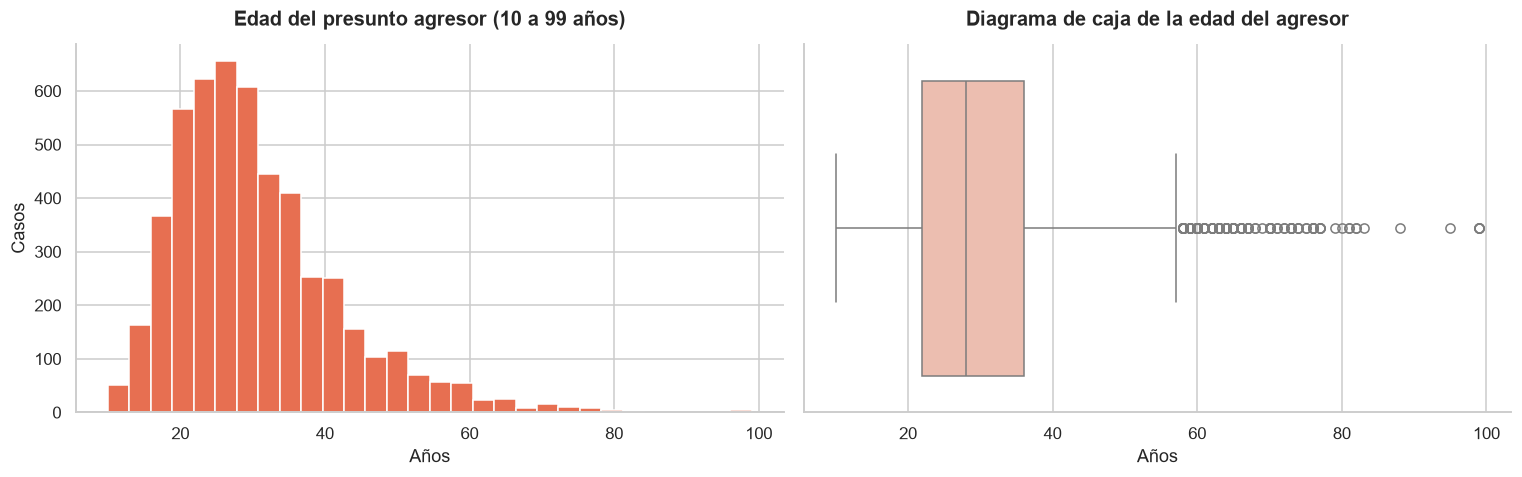

Año: de 2015 a 2025 | no numéricos: 0
Semana epidemiológica fuera de 1-53: 0


In [89]:
if S_EDAD_AGRE:
    edad = pd.to_numeric(siv[S_EDAD_AGRE], errors="coerce")
    texto = siv[S_EDAD_AGRE]
    print("Edad del agresor:")
    print(f"  vacíos: {int(texto.isna().sum()):,} | textos no numéricos: {int((edad.isna() & texto.notna()).sum()):,}")
    print(f"  fuera de 10-99 años: {int((edad.notna() & ~edad.between(10, 99)).sum()):,}")
    print("  valores fuera de rango más comunes:", edad[edad.notna() & ~edad.between(10, 99)].value_counts().head(5).to_dict())
    display(edad.describe().round(1).to_frame("edad del agresor"))
    r = resumen_iqr(edad[edad.between(10, 99)])
    print(f"  Outliers por IQR dentro del rango válido: {r['outliers']:,} (por fuera de {r['lim_inf']:.0f} a {r['lim_sup']:.0f} años)")

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    e = edad[edad.between(10, 99)]
    axes[0].hist(e, bins=30, color=FUENTES["sivigila"]["color"])
    axes[0].set_title("Edad del presunto agresor (10 a 99 años)")
    axes[0].set_xlabel("Años")
    axes[0].set_ylabel("Casos")
    sns.boxplot(x=e, ax=axes[1], color="#F6B8A6")
    axes[1].set_title("Diagrama de caja de la edad del agresor")
    axes[1].set_xlabel("Años")
    plt.tight_layout()
    guardar("19_siv_edad_agresor.png")
    plt.show()

if S_ANIO:
    anio_s = pd.to_numeric(siv[S_ANIO], errors="coerce")
    print(f"Año: de {anio_s.min():.0f} a {anio_s.max():.0f} | no numéricos: {int(anio_s.isna().sum())}")
if S_SEMANA:
    sem = pd.to_numeric(siv[S_SEMANA], errors="coerce")
    print(f"Semana epidemiológica fuera de 1-53: {int((sem.notna() & ~sem.between(1, 53)).sum())}")

### 5.6 Alcance geográfico y comuna

Esta es la revisión más importante para la integración. Si la comuna de SIVIGILA se puede llevar al mismo número de comuna que usa el OSEC (del 1 al 17), las dos fuentes se pueden comparar comuna por comuna. Para asignar la comuna se normaliza el texto (mayúsculas, sin tildes) y se aplican estas reglas, en orden:

1. Si el valor empieza con un número seguido de punto ("08. SUR OCCIDENTE"), se usa ese **número**, porque es más confiable que el nombre. Los nombres cambian entre fuentes ("LA CIUDADELA" en SIVIGILA es "CIUDADELA REAL DE MINAS" en el OSEC, y la comuna 16 aparece como "LAGOS DEL CACIQUE" y como "TEJAR"), pero el número es el mismo. Los números del 21 al 30 corresponden a comunas de Floridablanca y no se asignan
2. Si no hay número al inicio, se busca el **nombre** de la comuna del OSEC dentro del texto
3. Los corregimientos ("CORREG. 3") se llevan al corregimiento correspondiente, igual que en el OSEC

In [90]:
if S_MUN:
    print("Municipios en el archivo:")
    display(tabla_frecuencias(siv[S_MUN], top=8))

# Catálogo de comunas a partir del scraping: "01. NORTE" -> 1: "NORTE"
catalogo = {}
for c in osec["comuna"].unique():
    m = re.match(r"^(\d{2})\.\s+(.+)$", c)
    if m:
        catalogo[int(m.group(1))] = sin_tildes(m.group(2))
print("Catálogo de comunas del OSEC:", catalogo)


def comuna_a_numero(valor):
    # 1) Si empieza con "NN." se usa el número ("08. SUR OCCIDENTE" -> 8)
    # 2) Si no hay número al inicio, se busca el nombre de la comuna del OSEC dentro del texto
    if pd.isna(valor):
        return None
    s = sin_tildes(valor)
    m = re.match(r"^(\d{1,2})\s*\.", s)
    if m:
        n = int(m.group(1))
        return n if 1 <= n <= 17 else None      # 21 a 30 son comunas de Floridablanca
    for num, nombre in sorted(catalogo.items(), key=lambda x: -len(x[1])):   # primero los nombres largos
        if re.search(r"\b" + re.escape(nombre) + r"\b", s):
            return num
    return None


def corregimiento(valor):
    # "CORREG. 3" -> 3
    if pd.isna(valor):
        return None
    m = re.search(r"CORREG\w*\.?\s*(\d)", sin_tildes(valor))
    return int(m.group(1)) if m else None


if S_COMUNA:
    valores = siv[S_COMUNA].value_counts(dropna=False)
    cruce = pd.DataFrame({"casos": valores})
    cruce["numero_comuna"] = [comuna_a_numero(v) for v in cruce.index]
    cruce["nombre_osec"] = cruce["numero_comuna"].map(catalogo)
    cruce["corregimiento"] = [corregimiento(v) for v in cruce.index]
    cubiertos = cruce.loc[cruce["numero_comuna"].notna(), "casos"].sum()
    en_correg = cruce.loc[cruce["corregimiento"].notna(), "casos"].sum()
    print(f"\nValores distintos de la comuna en SIVIGILA: {len(cruce)}")
    print(f"Casos cuya comuna se pudo llevar al número del OSEC: {cubiertos:,} de {len(siv):,} ({cubiertos / len(siv) * 100:.1f}%)")
    print(f"Casos en corregimientos: {en_correg:,}")
    print("\nValores más frecuentes y su comuna asignada:")
    display(cruce.head(20))
    print("Valores que NO se pudieron asignar:")
    display(cruce[cruce["numero_comuna"].isna() & cruce["corregimiento"].isna()].head(15))

Municipios en el archivo:


,casos,pct
Municipio,,
BUCARAMANGA,17003,99.4
VENEZUELA - SIN ESPECIFICACIÓN ADICIONAL DE LUGAR,22,0.1
PIEDECUESTA,11,0.1
GIRON,7,0.0
FLORIDABLANCA,5,0.0
* SANTANDER. MUNICIPIO DESCONOCIDO,5,0.0
EL PLAYON,4,0.0
LEBRIJA,4,0.0


Catálogo de comunas del OSEC: {1: 'NORTE', 2: 'NORORIENTAL', 3: 'SAN FRANCISCO', 4: 'OCCIDENTAL', 5: 'GARCIA ROVIRA', 6: 'LA CONCORDIA', 7: 'CIUDADELA REAL DE MINAS', 8: 'SUROCCIDENTE', 9: 'LA PEDREGOSA', 10: 'PROVENZA', 11: 'SUR', 12: 'CABECERA DEL LLANO', 13: 'ORIENTAL', 14: 'MORRORICO', 15: 'CENTRO', 16: 'TEJAR', 17: 'MUTIS'}

Valores distintos de la comuna en SIVIGILA: 37
Casos cuya comuna se pudo llevar al número del OSEC: 15,050 de 17,104 (88.0%)
Casos en corregimientos: 138

Valores más frecuentes y su comuna asignada:


,casos,numero_comuna,nombre_osec,corregimiento
Comuna,,,,
03. SAN FRANCISCO,2768,3.0,SAN FRANCISCO,NaN
01. NORTE,2027,1.0,NORTE,NaN
SIN INFORMACION,1538,NaN,NaN,NaN
04. OCCIDENTAL,1378,4.0,OCCIDENTAL,NaN
13. ORIENTAL,1074,13.0,ORIENTAL,NaN
02. NORORIENTAL,1021,2.0,NORORIENTAL,NaN
11. SUR,910,11.0,SUR,NaN
05. GARCIA ROVIRA,865,5.0,GARCIA ROVIRA,NaN
10. PROVENZA,841,10.0,PROVENZA,NaN


Valores que NO se pudieron asignar:


,casos,numero_comuna,nombre_osec,corregimiento
Comuna,,,,
SIN INFORMACION,1538,NaN,NaN,NaN
FLORIDABLANCA,96,NaN,NaN,NaN
24. CALDAS - REPOSO,79,NaN,NaN,NaN
GIRON,61,NaN,NaN,NaN
25. BOSQUES - MOLINOS,34,NaN,NaN,NaN
30. CORREG,29,NaN,NaN,NaN
27. VILLABEL-SANTA ANA,27,NaN,NaN,NaN
21. FLORIDA - CASCO ANTIGUO,18,NaN,NaN,NaN
28. LA CUMBRE - CARMEN,12,NaN,NaN,NaN


### 5.7 Variables clave, estadísticas básicas y gráficas

In [91]:
claves_siv = [c for c in [S_ANIO, S_SEXO, S_CICLO, S_DEFNAT, S_PAREN, S_AREA, S_COMUNA, S_CONFIN, S_ESC] if c]
filas = []
for c in claves_siv:
    vc = siv[c].value_counts()
    filas.append({"variable": c, "categorias": int(vc.size), "mas_frecuente": corto(vc.index[0], 40),
                  "casos": int(vc.iloc[0]), "pct": round(vc.iloc[0] / len(siv) * 100, 1), "nulos": int(siv[c].isna().sum())})
display(pd.DataFrame(filas).set_index("variable"))

if S_SEXO:
    print("Sexo de la víctima:", tabla_frecuencias(siv[S_SEXO])["casos"].to_dict())
if S_CONFIN:
    print("Condición final (con_fin_):", tabla_frecuencias(siv[S_CONFIN])["casos"].to_dict())
if S_AREA:
    print("Área del hecho (area_):", tabla_frecuencias(siv[S_AREA])["casos"].to_dict())

,categorias,mas_frecuente,casos,pct,nulos
variable,,,,,
año,11,2016,2141,12.5,0
sexo_,2,Femenino,11835,69.2,0
Ciclo de vida,6,Primera infancia,4836,28.3,0
def_naturaleza,11,Negligencia y abandono,6173,36.1,0
parentezco_vict,25,Madre,5143,30.1,0
area_,3,CABECERA MUNICIPAL,16677,97.5,0
Comuna,37,03. SAN FRANCISCO,2768,16.2,0
con_fin_,3,1,17069,99.8,0
escenario,11,2,11314,66.1,0


Sexo de la víctima: {'Femenino': 11835, 'Masculino': 5269}
Condición final (con_fin_): {'1': 17069, '2': 26, '0': 9}
Área del hecho (area_): {'CABECERA MUNICIPAL': 16677, 'RURAL DISPERSO': 242, 'CENTRO POBLADO': 185}


2026-10-13 15:54:37,231 - [INFO] - matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-13 15:54:37,234 - [INFO] - matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


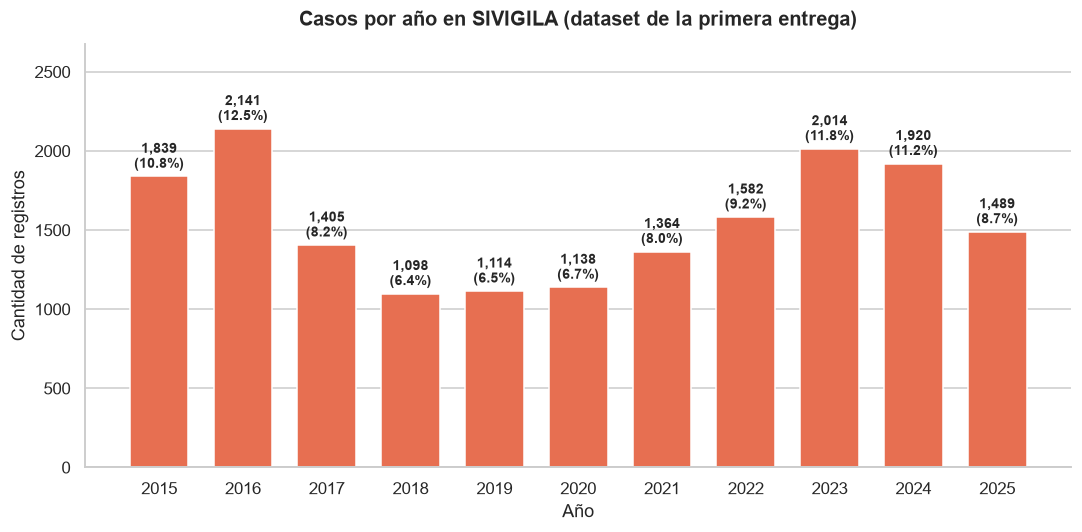

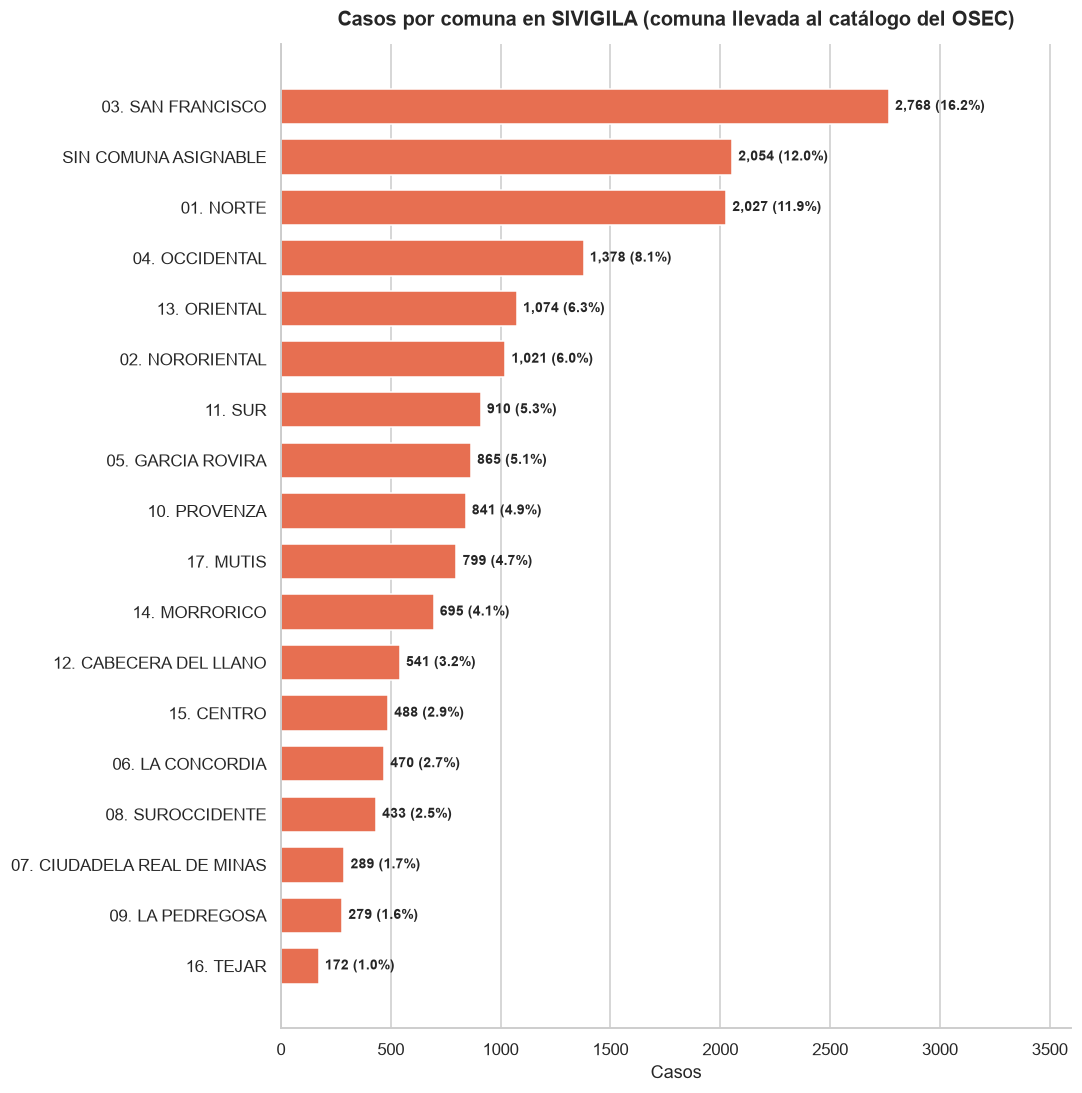

Vista previa del turno con etl/turno.py:


,casos,pct
hora_hecho,,
NO REPORTADO,12292,71.9
TARDE,2596,15.2
MAÑANA,1376,8.0
NOCHE,840,4.9


In [92]:
if S_ANIO:
    barras_verticales(siv[S_ANIO].value_counts().sort_index(), "Casos por año en SIVIGILA (dataset de la primera entrega)",
                      "Año", "20_siv_casos_por_anio.png", color=FUENTES["sivigila"]["color"])
if S_COMUNA:
    num_comuna = siv[S_COMUNA].map(comuna_a_numero)
    conteo_c = num_comuna.map(lambda x: f"{int(x):02d}. {catalogo[int(x)]}" if pd.notna(x) else "SIN COMUNA ASIGNABLE").value_counts()
    barras_horizontales(conteo_c, "Casos por comuna en SIVIGILA (comuna llevada al catálogo del OSEC)",
                        "Casos", "21_siv_casos_por_comuna.png", color=FUENTES["sivigila"]["color"])
if S_HORA:
    turnos_siv = siv[S_HORA].map(calcular_turno)
    print("Vista previa del turno con etl/turno.py:")
    display(tabla_frecuencias(turnos_siv))

### 5.8 Observaciones de SIVIGILA

- Es la fuente con más detalle por caso (comuna, barrio, hora exacta, edad del agresor, condición final), por eso sigue siendo el centro del modelo
- La hora viene en 12 horas con "a. m." / "p. m." y la medianoche exacta funciona como marcador de hora desconocida. `etl/turno.py` ya la trata como `NO REPORTADO`
- La edad del agresor tiene valores por fuera de 10 a 99 años (incluidos ceros y vacíos), que en la transformación se dejan como edad desconocida y no se descartan los casos
- La comuna viene casi siempre como "NN. NOMBRE", igual que en el OSEC, así que la gran mayoría de los casos se puede llevar al número de comuna. Como algunos nombres cambian entre fuentes ("LA CIUDADELA" y "CIUDADELA REAL DE MINAS", "LAGOS DEL CACIQUE" y "TEJAR", "SUR OCCIDENTE" y "SUROCCIDENTE"), la unión se hace por el **número** y no por el nombre
- También aparecen comunas de otros municipios (las numeradas del 21 al 30 son de Floridablanca, y valores como "GIRON" o "FLORIDABLANCA"), el valor "SIN INFORMACION" y corregimientos escritos como "CORREG. 3". Los dos primeros quedan como SIN COMUNA y los corregimientos se llevan a CORREGIMIENTO 1, 2 o 3, igual que en el OSEC
- Los textos vienen con tildes y mayúsculas mezcladas, que la transformación ya unifica con `normalizar_cadena`

## Parte 6. Hallazgos y reglas de transformación

### 6.1 Resumen calculado

Esta celda arma el resumen con lo que acaba de calcular el notebook, así los números no se quedan desactualizados cuando se vuelve a ejecutar

In [93]:
print("HALLAZGOS DEL EDA (calculados al ejecutar)\n")
print(f"1. Volumen: {TOTAL_REGISTROS:,} registros en total")
for nombre, fila in resumen.iterrows():
    print(f"     {nombre}: {fila['registros']:,} filas, {fila['columnas']} columnas, {fila['celdas vacías (%)']}% de celdas vacías")

print(f"\n2. Scraping OSEC: {o['periodo'].nunique()} boletines ({o['periodo'].min()} a {o['periodo'].max()}), "
      f"{len(o):,} filas, {dup_llave} duplicados en la llave")
print(f"     Serie mensual reconstruida: {len(serie)} meses ({serie.index.min()} a {serie.index.max()})")
print(f"     Meses corregidos entre boletines: {(rev['correccion'] != 0).mean() * 100:.1f}% de los meses-comuna publicados dos veces")
print(f"     Variaciones de ±100 % o más: {len(extremas)} filas, casi todas con bases de 5 casos o menos")

print(f"\n3. API Medicina Legal: {len(api_bga):,} casos de Bucaramanga, {len(mujeres_api):,} con víctima mujer "
      f"({len(mujeres_api) / len(api_bga) * 100:.1f}%)")
print(f"     Nulos reales: {pct_vacio(api_bga)}% | celdas 'sin información': "
      f"{sin_dato_api['valores_sin_dato'].sum() / api_bga.size * 100:.1f}%")
casi_vacias = sin_dato_api[sin_dato_api["pct"] >= 90].index.tolist()
print(f"     Columnas con 90 % o más sin dato: {casi_vacias}")
print(f"     Filas repetidas sin id: {dup_api}")
print(f"     Muestra nacional para comparar: {len(api_nal):,} registros de los años {anios_nal}")

print(f"\n4. Vivienda ECV 2024: {len(vb):,} viviendas de Bucaramanga; {int(en_alcance.sum()):,} con estrato 1 a 6 "
      f"({en_alcance.mean() * 100:.1f}%)")

print(f"\n5. SIVIGILA: {len(siv):,} casos | filas repetidas sin '{S_ORDEN}': {dup_siv}")
if S_COMUNA:
    print(f"     Casos con comuna asignable al catálogo del OSEC: {cubiertos / len(siv) * 100:.1f}%")

HALLAZGOS DEL EDA (calculados al ejecutar)

1. Volumen: 156,940 registros en total
     Scraping - OSEC Bucaramanga: 1,344 filas, 14 columnas, 0.0% de celdas vacías
     API - Bucaramanga completa: 3,386 filas, 36 columnas, 0.0% de celdas vacías
     API - muestra nacional: 50,000 filas, 36 columnas, 0.0% de celdas vacías
     CSV - vivienda ECV 2024 (nacional): 85,106 filas, 6 columnas, 0.62% de celdas vacías
     CSV - SIVIGILA (entrega 1): 17,104 filas, 32 columnas, 2.2% de celdas vacías

2. Scraping OSEC: 16 boletines (202505 a 202608), 1,344 filas, 0 duplicados en la llave
     Serie mensual reconstruida: 28 meses (202405 a 202608)
     Meses corregidos entre boletines: 61.9% de los meses-comuna publicados dos veces
     Variaciones de ±100 % o más: 326 filas, casi todas con bases de 5 casos o menos

3. API Medicina Legal: 3,386 casos de Bucaramanga, 1,936 con víctima mujer (57.2%)
     Nulos reales: 0.0% | celdas 'sin información': 14.6%
     Columnas con 90 % o más sin dato: ['t

### 6.2 De hallazgo a regla de transformación

Esta tabla es el puente entre el EDA y el código. Cada fila dice qué encontramos, qué va a hacer la transformación con eso y cómo lo vamos a verificar con Great Expectations antes de cargar al Data Warehouse

**Reglas generales (todas las fuentes)**

| Hallazgo | Regla de transformación | Validación (Great Expectations) |
|---|---|---|
| Todas las fuentes llegan como texto | Se convierten a número solo las columnas que son cantidades (casos, año, días, edad). Los códigos (DANE, estrato, zona) siguen como texto o como código entero según el modelo | Tipos de columna esperados en cada tabla |
| La falta de dato viene escrita de muchas formas ("Sin información", "No aplica", "NO DISPONIBLE", vacío) | Todas se unifican en `NO REPORTADO`, el valor que ya usa el modelo de la primera entrega | Ninguna columna categórica del modelo tiene nulos ni textos de "sin dato" distintos a `NO REPORTADO` |
| Los textos tienen tildes y mayúsculas mezcladas | `normalizar_cadena`: MAYÚSCULAS, sin tildes y sin espacios dobles (excepto el turno, que conserva "MAÑANA") | Valores dentro de los catálogos definidos |
| El enfoque es Bucaramanga y víctimas mujeres | Se filtra el municipio 68001 y, en las fuentes de casos, sexo de la víctima = mujer. Las capas crudas guardan todo | Todas las filas de los hechos son de Bucaramanga; en `hechos_violencia` todas las víctimas son mujeres |

**Scraping OSEC**

| Hallazgo | Regla de transformación | Validación |
|---|---|---|
| Cifras con formato colombiano ("1.128", "13,95") | Quitar el punto de miles y cambiar la coma decimal por punto antes de convertir | Casos enteros y mayores o iguales a 0 |
| La comuna viene como "01. NORTE" | Separar en `numero_comuna` (1 a 17) y `nombre_comuna`. Corregimientos y NO DISPONIBLE quedan con número nulo y una categoría propia | Exactamente 21 filas por periodo, delito y bloque |
| La variación del PDF no existe cuando el año anterior tiene 0 casos | No usar la variación del PDF: recalcularla y dejarla vacía si el año anterior es 0 | La diferencia es igual a actual menos anterior |
| Los años del encabezado del PDF pueden estar mal | Tomar los años del periodo del boletín | `anio_actual` = primeros 4 dígitos del periodo |
| La Policía corrige meses anteriores entre boletines | Construir la serie mensual con la cifra del boletín más reciente que publicó cada mes | Un solo valor por mes, comuna y delito |
| Acumulado y mes son dos vistas del mismo dato | Guardar el bloque como columna y nunca sumar entre bloques | `bloque` solo toma ACUMULADO o MES |
| Variaciones extremas con bases pequeñas | No se eliminan; en los tableros la variación siempre se muestra junto al número de casos | Sin validación (es un dato real) |

**API Medicina Legal**

| Hallazgo | Regla de transformación | Validación |
|---|---|---|
| Columnas con 90 % o más sin dato (identidad de género, transgénero, pueblo indígena, pertenencia grupal, entre otras) | No pasan al modelo | Sin validación (no se cargan) |
| Hora en rangos de 3 horas | `calcular_turno` convierte el rango al turno (MAÑANA, TARDE, NOCHE, NO REPORTADO) | Turno dentro de los 4 valores permitidos |
| Códigos DANE sin el cero inicial en la muestra nacional | `zfill(5)` para municipio y `zfill(2)` para departamento, guardados como texto | Código de municipio con 5 dígitos |
| Categorías con nombres distintos a SIVIGILA (agresor, ciclo vital, escenario) | Tabla de homologación hacia categorías comunes (por ejemplo, "Hermano (a)", "Tío (a)" y "Cuñado (a)" a OTRO FAMILIAR; "(18 a 28) Juventud" y "Jovenes" a JUVENTUD) | Valores dentro del catálogo homologado |
| Filas repetidas sin el id | No se borran (datos anonimizados); el `id` se usa como llave única | `id` único y no nulo |
| Días de incapacidad publicados en rangos y escritos de varias formas | Convertir a categoría ordenada: CERO DIAS, 1 A 30, 31 A 90, MAS DE 90, NO REPORTADO; no se eliminan los casos graves | Valor dentro de las 5 categorías |
| La fuente no incluye violencia de pareja | Se documenta como alcance de la fuente; al comparar con SIVIGILA por agresor se usan solo las categorías familiares | Sin validación |
| Una misma categoría escrita de varias formas ("Hermano (a)" / "Hermano(a)", mes en minúscula y mayúscula) | Normalizar (mayúsculas, sin tildes, sin espacio antes del paréntesis) y convertir el nombre del mes a número | Mes entre 1 y 12 |

**CSV de vivienda**

| Hallazgo | Regla de transformación | Validación |
|---|---|---|
| Archivo nacional | Filtrar `P1_DEPARTAMENTO = 68` y `P1_MUNICIPIO = 001` al cargar | Todas las filas con id del municipio de Bucaramanga |
| Códigos 0, 8, 9 y vacío no son estrato | Cargar solo estratos 1 a 6 y registrar cuántas viviendas se excluyen | `id_estrato` entre 1 y 6 |
| Estrato vacío solo cuando no hay energía | Se conserva `tiene_energia_electrica` como control | Si hay estrato 1 a 6, entonces energía = 1 |
| Duplicados normales de encuesta | No se eliminan | Sin validación |
| `CLASE` es la zona (1 cabecera, 2 centro poblado) | Se relaciona con el área de `dim_municipio` | `zona_vivienda` en {1, 2, 3} |

**SIVIGILA (primera entrega)**

| Hallazgo | Regla de transformación | Validación |
|---|---|---|
| "12:00:00 a. m." funciona como hora desconocida | Se trata como `NO REPORTADO` (`MEDIANOCHE_ES_PLACEHOLDER = True` en `etl/turno.py`) | Turno dentro de los 4 valores permitidos |
| Edad del agresor fuera de 10 a 99 o vacía | Edad desconocida (nula); el caso se conserva | `edad_agre` nula o entre 10 y 99 |
| Comuna escrita de varias formas y con nombres distintos al OSEC | Llevar al número de comuna (el número tiene prioridad sobre el nombre); "CORREG. n" a CORREGIMIENTO n; comunas de otros municipios y SIN INFORMACION a SIN COMUNA | Comuna dentro del catálogo de `dim_comuna` |
| Fechas en más de un formato | `_parsear_fecha` acepta año primero y día primero; lo que no se entienda queda nulo y el año sale de la columna `año` | Fecha no posterior a la fecha de carga |

### 6.3 Cómo se pueden unir las fuentes

Ninguna fuente se puede unir con otra fila por fila, porque cada una mide algo distinto. Lo que sí se puede hacer es compararlas a través de variables comunes, y eso define cómo se arma el conjunto unificado y enriquecido en la transformación:

| Fuentes | Variable común | Cómo se usa |
|---|---|---|
| SIVIGILA y OSEC | Número de comuna (1 a 17) y año | Comparar casos atendidos en salud con denuncias, comuna por comuna |
| SIVIGILA y API | Año, sexo, ciclo de vida, agresor homologado y turno | Comparar el perfil de los casos entre dos fuentes oficiales |
| API y OSEC | Año (la API llega a 2024 y el OSEC trae desde 2024 hasta 2026) | Extender la línea de tiempo de la ciudad |
| Vivienda y SIVIGILA | Zona (cabecera / centro poblado) mediante `dim_municipio` | Contexto socioeconómico por zona |
| Todas | Municipio 68001 | Todas quedan conectadas a la misma fila de Bucaramanga en `dim_municipio` |

Para que estas uniones sean confiables, en la transformación vamos a agregar el **código DANE** a `dim_municipio` (hoy solo tiene el nombre) y una **dimensión de comuna** con el número y el nombre de las 17 comunas, tomados del OSEC

### 6.4 Cierre

El EDA confirma que las 4 fuentes tienen la calidad suficiente para el pipeline, siempre que se apliquen las reglas de la tabla anterior. Los puntos más delicados son tres: la falta de dato escrita de muchas formas, las categorías con nombres distintos entre SIVIGILA y la API (que necesitan homologación) y las correcciones que hace la Policía a sus cifras entre boletines. Los tres quedan resueltos en la transformación y vigilados con Great Expectations, para que al Data Warehouse solo lleguen datos que cumplan estas reglas